
<div style="background: linear-gradient(135deg, #1a1a2e 0%, #16213e 50%, #0f3460 100%); 
            padding: 60px 40px; border-radius: 16px; text-align: center; margin-bottom: 30px;">
  <h1 style="color: #e94560; font-size: 2.4em; margin-bottom: 10px; letter-spacing: 2px;">
      TEXT MINING 
  </h1>
  <h2 style="color: #f0f0f0; font-size: 1.4em; font-weight: 300; margin-bottom: 20px;">
    Conception et optimisation de pipelines de classification des SMS indésirables<br>
  </h2>
  <hr style="border-color: #e94560; width: 60%; margin: 20px auto;">
  <p style="color: #aaaaaa; font-size: 1em;">
     Master — Traitement Automatique du Langage &nbsp;|&nbsp;  2025-2026
  </p>
</div>



## Introduction

Ce projet porte sur la classification automatique des SMS afin de distinguer les messages légitimes (*Ham*) des messages indésirables (*Spam*), à l’aide des techniques de traitement automatique du langage naturel (NLP) et de Machine Learning. Il consiste à comparer différentes méthodes de nettoyage, de prétraitement et de vectorisation textuelle, ainsi que plusieurs modèles de classification. Des techniques de **Data Augmentation** et de **rééquilibrage des classes par SMOTE** sont également étudiées afin d’évaluer leur impact sur les performances des modèles. Enfin, les résultats sont comparés à l’aide de métriques telles que l’accuracy, la précision, le rappel et le F1-score, afin d’identifier les approches les plus adaptées à la détection des SMS indésirables.


## Partie 1 — Nettoyage des Données


### Objectif de cette partie

Avant d’entraîner un modèle de Machine Learning sur du texte, il faut comprendre que :

       Les algorithmes ne comprennent pas le langage humain

       Ils manipulent uniquement des nombres

Mais avant même la vectorisation, on doit :

✔ Explorer les données

✔ Comprendre leur structure

✔ Identifier le bruit (noise)

✔ Nettoyer intelligemment

#### 1️- Chargement du Dataset


In [1]:
import pandas as pd
from pathlib import Path

# Racine du projet : fonctionne depuis notebooks/ ou depuis la racine du dépôt
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
EMB_DIR = ROOT / "embeddings"   # embeddings pré-entraînés (non versionnés, voir README)
FIG_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_DIR / "raw" / "SMSSpamCollection", sep="\t", header=None)
df.columns = ["label", "message"]

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Le dataset est un fichier texte où :

      colonne 1 → label (ham / spam)

      colonne 2 → message SMS

Le séparateur est une tabulation (\t).

On renomme les colonnes pour plus de clarté :
     label → classe  

     message → texte

### 2-  Analyse Exploratoire

   - Nombre total d’exemples

In [2]:
df.shape

(5572, 2)

- Répartition des classes

    -  C’est important ce que on vérifie si le dataset est déséquilibré.

In [3]:
df['label'].value_counts()

label
ham     4825
spam     747
Name: count, dtype: int64

Il y a beaucoup plus de messages normaux.

     Problème potentiel :

     Un modèle pourrait prédire toujours "ham" et avoir une bonne accuracy → illusion de performance

- Longueur des messages
   
    - On calcule :

       longueur en caractères

        moyenne
        
        min / max

In [4]:
df['length'] = df['message'].apply(len)
df['length'].describe()

count    5572.000000
mean       80.489950
std        59.942907
min         2.000000
25%        36.000000
50%        62.000000
75%       122.000000
max       910.000000
Name: length, dtype: float64

- Comparaison Spam vs Ham

In [5]:
df.groupby('label')['length'].mean()

label
ham      71.482487
spam    138.670683
Name: length, dtype: float64

      Observation fréquente : Spam souvent plus longs (promotions,URLs,appels à l’action)



### 3- Inspection qualitative du texte
- Détection simple via regex

    - Présence de chiffres

In [6]:
df['message'].str.contains(r'\d').sum()

1463

 
- Présence d’URLs

In [7]:
df['message'].str.contains(r'http|www').sum()

108

- Majuscules

In [8]:
df['message'].str.contains(r'[A-Z]').sum()

5463

On faire ça pour comprendre :

      Nature du bruit
      Décider quoi nettoyer
      Éviter de supprimer des infos utiles

### 4️- Nettoyage Minimal
- Objectif

    Réduire le bruit inutile sans détruire le signal informatif.

- Étapes demandées

      Mise en minuscules
      Suppression ponctuation
      Suppression chiffres
      Suppression caractères spéciaux
      Suppression stopwords
- Fonction de nettoyage

In [9]:
import sys
print(sys.executable)

c:\Users\0oo-u\AppData\Local\Programs\Python\Python311\python.exe


In [10]:
!{sys.executable} -m pip install nltk


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import re
import string
import nltk

# Vérification / téléchargement des stopwords
try:
    from nltk.corpus import stopwords
    stop_words = set(stopwords.words('english'))
except LookupError:
    nltk.download('stopwords')
    from nltk.corpus import stopwords
    stop_words = set(stopwords.words('english'))

def clean_text(text):
    
    # 1️ Mise en minuscules
    text = text.lower()
    
    # 2️ Suppression des chiffres
    text = re.sub(r'\d+', '', text)
    
    # 3️ Suppression de la ponctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    
    # 4️ Suppression des caractères spéciaux
    text = re.sub(r'\W+', ' ', text)
    
    # 5️ Suppression des stopwords
    tokens = text.split()
    tokens = [word for word in tokens if word not in stop_words]
    
    return " ".join(tokens)

- Application du nettoyage

In [75]:
df['clean_message'] = df['message'].apply(clean_text)

df[['message', 'clean_message']].head()

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though


In [13]:
print(df.columns)

Index(['label', 'message', 'length', 'clean_message'], dtype='object')


Le nettoyage améliore-t-il toujours ?

      NON.

Pourquoi ?
Oui il réduit bruit mais il se peutque le nettoyage agressif supprimer les signaux spam (majuscules,chiffres,
ponctuation agressive)

### - Conclusion Partie Nettoyage


Le nettoyage permet de standardiser le texte et réduire le bruit. Cependant, un nettoyage excessif peut supprimer des indices discriminants importants dans la détection de spam, notamment les chiffres, la ponctuation expressive et les majuscules.



## Partie 2 — Prétraitement Linguistique
   ### Objectif 
Après le nettoyage, on s’intéresse à la structure linguistique du texte.

        Transformer le texte brut en unités exploitables
        Réduire la variabilité des mots
        Améliorer la généralisation du modèle
 
On va comparer :

        Tokenisation
        Suppression des stopwords
        Stemming
        Lemmatisation
### 1️- Tokenisation
 La tokenisation consiste à découper un texte en unités appelées tokens.

In [14]:
from nltk.tokenize import word_tokenize
nltk.download('punkt')

def tokenize_text(text):
    return word_tokenize(text)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\0oo-u\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


### 2- Suppression des Stopwords
 Les stopwords : sont des mots très fréquents (the,is,at,on,and) avec une faible valeur sémantique

In [15]:
from nltk.corpus import stopwords
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def remove_stopwords(tokens):
    return [word for word in tokens if word.lower() not in stop_words]

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\0oo-u\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


- Attention 

Dans spam detection certains stopwords peuvent être informatifs

   Exemple : "You have won"
   
"You" et "have" peuvent aider le modèle.
### 3- Stemming
Le stemming réduit un mot à sa racine brute. C est une méthode rapide mais parfois agressive.

In [16]:

from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

def stem_tokens(tokens):
    return [stemmer.stem(word) for word in tokens]


### 4- Lemmatisation
La lemmatisation ramène un mot à sa forme canonique (lemme).Plus précis que stemming
| Mot     | Lemma |
| ------- | ----- |
| better  | good  |
| running | run   |
| studies | study |


In [17]:
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')

lemmatizer = WordNetLemmatizer()

def lemmatize_tokens(tokens):
    return [lemmatizer.lemmatize(word) for word in tokens]

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\0oo-u\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


### Construction des Versions Demandées
- Prétraitement Minimal

    - Tokenisation + Stopwords

In [18]:

def preprocess_minimal(text):
    tokens = word_tokenize(text)
    tokens = remove_stopwords(tokens)
    return " ".join(tokens)


- Prétraitement Avancé

In [19]:
#  Prétraitement avancé 1 : Tokenisation + Stopwords + Stemming
def preprocess_advanced_stem(text):
    tokens = word_tokenize(text)
    tokens = remove_stopwords(tokens)
    tokens = stem_tokens(tokens)
    return " ".join(tokens)


#  Prétraitement avancé 2 : Tokenisation + Stopwords + Lemmatisation
def preprocess_advanced_lemma(text):
    tokens = word_tokenize(text)
    tokens = remove_stopwords(tokens)
    tokens = lemmatize_tokens(tokens)
    return " ".join(tokens)

- Application des prétraitements

In [20]:
df['minimal'] = df['clean_message'].apply(preprocess_minimal)
df['advanced_stem'] = df['clean_message'].apply(preprocess_advanced_stem)
df['advanced_lemma'] = df['clean_message'].apply(preprocess_advanced_lemma)

# Vérification
print(df[['clean_message','minimal','advanced_stem','advanced_lemma']].head())

                                       clean_message  \
0  go jurong point crazy available bugis n great ...   
1                            ok lar joking wif u oni   
2  free entry wkly comp win fa cup final tkts st ...   
3                u dun say early hor u c already say   
4        nah dont think goes usf lives around though   

                                             minimal  \
0  go jurong point crazy available bugis n great ...   
1                            ok lar joking wif u oni   
2  free entry wkly comp win fa cup final tkts st ...   
3                u dun say early hor u c already say   
4        nah dont think goes usf lives around though   

                                       advanced_stem  \
0  go jurong point crazi avail bugi n great world...   
1                              ok lar joke wif u oni   
2  free entri wkli comp win fa cup final tkt st m...   
3                u dun say earli hor u c alreadi say   
4          nah dont think goe usf live around 

### 1️. Différence entre Stemming et Lemmatisation ##

- Stemming (advanced_stem) : 
   - Réduit les mots à leur racine brute. 

   - Parfois non linguistique : "crazy" → "crazi", "available" → "avail".

   - Rapide, diminue la dimension du vocabulaire, mais peut créer des mots "cassés" qui n’existent pas dans le dictionnaire.

- Lemmatisation (advanced_lemma) :

   - Ramène les mots à leur forme canonique (lemma) en respectant la grammaire.

          Exemple : "goes" → "go", "lives" → "life".

    - Plus précis, conserves un vocabulaire compréhensible, mais un peu plus lent.

- Observation sur ton résultat :

  - "crazy" → "crazi" (stem) vs "crazy" (lemma)

  - "available" → "avail" (stem) vs "available" (lemma)

  - "goes" → "goe" (stem) vs "go" (lemma)

- Conclusion : La lemmatisation est plus linguistiquement correcte, le stemming est plus agressif et "approximate".

### 2. La suppression des stopwords est-elle toujours pertinente pour la détection de spam ? ##

- Les stopwords sont des mots très fréquents et souvent peu informatifs (the, is, at).

- Cependant, dans le spam, certains stopwords peuvent être utiles pour détecter des phrases types :

            "You have won" → "you", "have" sont informatifs !

            "Click here to claim" → "to" ou "here" a une valeur pour identifier le style spam.

- Conclusion :

   - Supprimer tous les stopwords peut parfois retirer des indices utiles pour la détection de spam.

   - On peut envisager :

      Supprimer les stopwords classiques, mais garder ceux qui apparaissent dans des phrases typiques de spam.

      Ou tester les deux approches et comparer les performances (expérimentation).

## Partie 3 — Vectorisation
 ###  Objectif
   Convertir es messages prétraités en représentations numériques exploitables par les modèles de machine learning.

In [21]:
import sys
print(sys.version)
print(sys.executable)

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
c:\Users\0oo-u\AppData\Local\Programs\Python\Python311\python.exe


In [22]:
!{sys.executable} -m pip install gensim 


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
!{sys.executable} -m pip install scikit-learn numpy


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
df['minimal']

0       go jurong point crazy available bugis n great ...
1                                 ok lar joking wif u oni
2       free entry wkly comp win fa cup final tkts st ...
3                     u dun say early hor u c already say
4             nah dont think goes usf lives around though
                              ...                        
5567    nd time tried contact u u pound prize claim ea...
5568                          ü b going esplanade fr home
5569                          pity mood soany suggestions
5570    guy bitching acted like id interested buying s...
5571                                       rofl true name
Name: minimal, Length: 5572, dtype: object

In [24]:
# ---------------------------
# 1️ Imports
# ---------------------------
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from gensim.models import Word2Vec, KeyedVectors
import numpy as np

# ==========================================================
# 2️ BAG OF WORDS
# ==========================================================
count_vect = CountVectorizer()
X_bow = count_vect.fit_transform(df['minimal'])
print("BoW shape:", X_bow.shape)

# ==========================================================
# 3️ TF-IDF
# ==========================================================
tfidf_vect = TfidfVectorizer()
X_tfidf = tfidf_vect.fit_transform(df['minimal'])
print("TF-IDF shape:", X_tfidf.shape)

# ==========================================================
# 4 WORD2VEC (entraîné sur ton dataset)
# ==========================================================
sentences = [text.split() for text in df['minimal']]

w2v_model = Word2Vec(
    sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4
)

def w2v_doc_vector(doc):
    words = doc.split()
    vectors = [w2v_model.wv[word] for word in words if word in w2v_model.wv]
    if len(vectors) == 0:
        return np.zeros(100)
    return np.mean(vectors, axis=0)

X_w2v = np.array([w2v_doc_vector(doc) for doc in df['minimal']])
print("Word2Vec shape:", X_w2v.shape)

# ==========================================================
# 5 GLOVE PRE-ENTRAÎNÉ
# ==========================================================
glove_path = EMB_DIR / "glove.6B.100d.txt"
if not glove_path.exists():
    raise FileNotFoundError(f"{glove_path} introuvable : voir la section 'Embeddings' du README.")

glove_model = {}

with open(glove_path, 'r', encoding='utf8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        vector = np.array(values[1:], dtype='float32')
        glove_model[word] = vector

def glove_doc_vector(doc):
    words = doc.split()
    vectors = [glove_model[word] for word in words if word in glove_model]
    if len(vectors) == 0:
        return np.zeros(100)
    return np.mean(vectors, axis=0)

X_glove = np.array([glove_doc_vector(doc) for doc in df['minimal']])
print("GloVe shape:", X_glove.shape)

# ==========================================================
# 6 FASTTEXT PRE-ENTRAÎNÉ
# ==========================================================
fasttext_path = EMB_DIR / "wiki-news-300d-1M.vec"
if not fasttext_path.exists():
    raise FileNotFoundError(f"{fasttext_path} introuvable : voir la section 'Embeddings' du README.")

ft_model = KeyedVectors.load_word2vec_format(
    str(fasttext_path),
    binary=False  
)

def ft_doc_vector(doc):
    words = doc.split()
    vectors = [ft_model[word] for word in words if word in ft_model]
    if len(vectors) == 0:
        return np.zeros(ft_model.vector_size)
    return np.mean(vectors, axis=0)

X_ft = np.array([ft_doc_vector(doc) for doc in df['minimal']])
print("FastText shape:", X_ft.shape)


BoW shape: (5572, 8475)
TF-IDF shape: (5572, 8475)
Word2Vec shape: (5572, 100)
GloVe shape: (5572, 100)
FastText shape: (5572, 300)


#### Interprétation des dimensions des représentations

BoW et TF-IDF produisent une matrice de dimension (5572, 8475), ce qui signifie 5572 documents et 8475 mots uniques. Ces représentations sont sparse et de grande dimension.

En revanche, Word2Vec (100d), GloVe (100d) et FastText (300d) génèrent des vecteurs denses et de faible dimension, capturant mieux la sémantique tout en réduisant la taille des données. FastText est plus riche (300 dimensions) mais plus coûteux en calcul.

#### 1 Quelle méthode capture le mieux la sémantique ?

BoW et TF-IDF : ils représentent les documents par la fréquence des mots (BoW) ou des poids pondérés (TF-IDF), mais ils ne connaissent pas le sens des mots. Exemple : “chien” et “canin” sont traités comme des mots totalement différents.

Word Embeddings (Word2Vec, GloVe, FastText) : chaque mot est représenté par un vecteur dense dans un espace sémantique. La moyenne des vecteurs par document permet de capturer le sens global et les relations entre mots.

Donc les embeddings capturent mieux la sémantique que BoW ou TF-IDF, car ils considèrent le contexte et la similarité entre mots.
#### 2 Pourquoi TF-IDF peut être plus performant que BoW ?

Les deux ont la même taille de vecteur : (5572, 8475) → chaque colonne = un mot du vocabulaire.

TF-IDF pondère les mots rares plus fortement et réduit l’importance des mots fréquents mais peu informatifs (“le”, “et”, etc.).

BoW se contente de compter les occurrences, ce qui donne beaucoup de bruit pour les mots très fréquents.

→ TF-IDF améliore la pertinence des mots dans la représentation et peut donc donner de meilleurs résultats en classification ou clustering.
#### 3 Avantages et limites des embeddings sur un petit dataset
Les embeddings représentent chaque document par un vecteur dense qui capture le sens des mots. Sur un petit dataset, Word2Vec entraîné localement peut être moins précis, car il n’a pas assez de données pour bien apprendre les relations entre mots. Les embeddings pré-entraînés comme GloVe ou FastText utilisent des connaissances de grands corpus et donnent de meilleurs vecteurs même avec peu de données. FastText est pratique pour les mots inconnus grâce aux sous-mots. La principale limite est que certains mots spécifiques au dataset peuvent ne pas être bien représentés, et que le modèle peut ne pas saisir toutes les nuances propres aux textes.

### PARTIE 4 — CLASSIFICATION & PARTIE 5 — ÉVALUATION

 ###  Objectif
Comparer l’efficacité de différentes vectorisations et modèles pour classifier correctement les textes.

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer

# ------------------------------
# 1 Transformer pour nettoyage minimal
# ------------------------------
# On utilise ta fonction clean_text existante
clean_transformer = FunctionTransformer(lambda x: [clean_text(doc) for doc in x])

# ------------------------------
# 2 Vectorizers
# ------------------------------
vectorizers = {
    "BoW": CountVectorizer(),
    "TF-IDF": TfidfVectorizer()
}

# ------------------------------
# 3 Embeddings déjà calculés
# ------------------------------
embedding_vectors = {
    "Word2Vec": X_w2v,
    "GloVe": X_glove,
    "FastText": X_ft
}

# ------------------------------
# 4 Modèles
# ------------------------------
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "SVM": SVC(kernel='linear'),
    "RandomForest": RandomForestClassifier(n_estimators=100)
}

# ------------------------------
# 5 Pipelines pour BoW et TF-IDF
# Nettoyage minimal + Vectorisation + Modèle
# ------------------------------
pipelines_text = {}
for vect_name, vect in vectorizers.items():
    for model_name, model in models.items():
        pipelines_text[f"{vect_name} + {model_name}"] = Pipeline([
            ('cleaner', clean_transformer),   # appel du nettoyage minimal
            ('vectorizer', vect),
            ('classifier', model)
        ])

# ------------------------------
# 6 Pipelines pour embeddings (Word2Vec, GloVe, FastText)
# Ici on ne met pas de vectorizer car embeddings sont déjà calculés
# ------------------------------
pipelines_embeddings = {}
for emb_name, X_emb in embedding_vectors.items():
    for model_name, model in models.items():
        pipelines_embeddings[f"{emb_name} + {model_name}"] = model

# ------------------------------
# 7 Résumé
# ------------------------------
print("Pipelines texte (Nettoyage min + Vectorisation + Modèle) :")
for name in pipelines_text.keys():
    print("-", name)

print("\nPipelines embeddings (modèles sur vecteurs pré-calculés) :")
for name in pipelines_embeddings.keys():
    print("-", name)

Pipelines texte (Nettoyage min + Vectorisation + Modèle) :
- BoW + LogisticRegression
- BoW + SVM
- BoW + RandomForest
- TF-IDF + LogisticRegression
- TF-IDF + SVM
- TF-IDF + RandomForest

Pipelines embeddings (modèles sur vecteurs pré-calculés) :
- Word2Vec + LogisticRegression
- Word2Vec + SVM
- Word2Vec + RandomForest
- GloVe + LogisticRegression
- GloVe + SVM
- GloVe + RandomForest
- FastText + LogisticRegression
- FastText + SVM
- FastText + RandomForest


### Évaluation finale de tous les pipelines

c:\Users\0oo-u\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])



Matrice de confusion pour Word2Vec + LogisticRegression:


c:\Users\0oo-u\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])



Matrice de confusion pour Word2Vec + SVM:

Matrice de confusion pour Word2Vec + RandomForest:

Matrice de confusion pour GloVe + LogisticRegression:

Matrice de confusion pour GloVe + SVM:

Matrice de confusion pour GloVe + RandomForest:

Matrice de confusion pour FastText + LogisticRegression:

Matrice de confusion pour FastText + SVM:

Matrice de confusion pour FastText + RandomForest:


,Pipeline,Accuracy,Precision,Recall,F1-score
0,TF-IDF + SVM,0.984450,0.985294,0.897321,0.939252
1,BoW + SVM,0.983254,0.985149,0.888393,0.934272
2,BoW + LogisticRegression,0.980263,0.994819,0.857143,0.920863
3,TF-IDF + RandomForest,0.976675,1.000000,0.825893,0.904645
4,BoW + RandomForest,0.973086,1.000000,0.799107,0.888337
5,GloVe + RandomForest,0.959330,0.969880,0.718750,0.825641
6,TF-IDF + LogisticRegression,0.958732,0.993631,0.696429,0.818898
7,FastText + SVM,0.951555,0.838863,0.790179,0.813793
8,FastText + RandomForest,0.956340,0.980892,0.687500,0.808399
9,Word2Vec + RandomForest,0.950359,0.949045,0.665179,0.782152


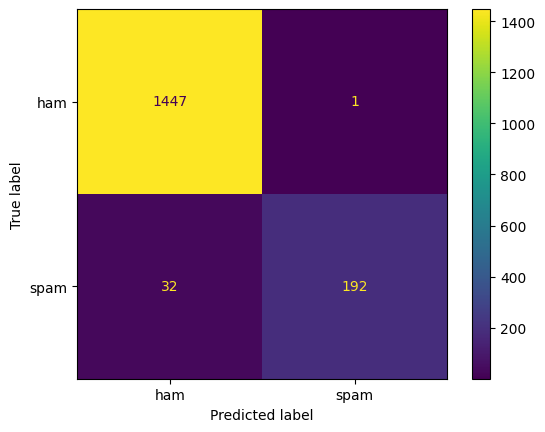

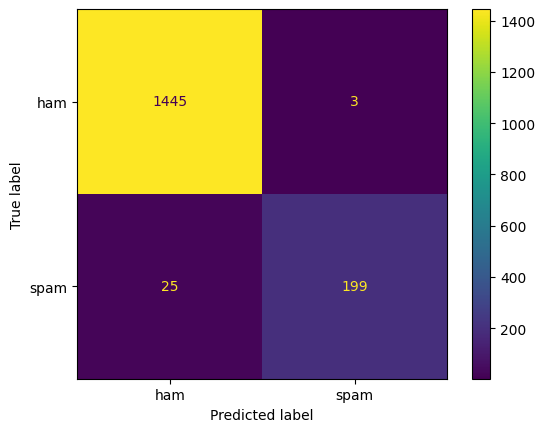

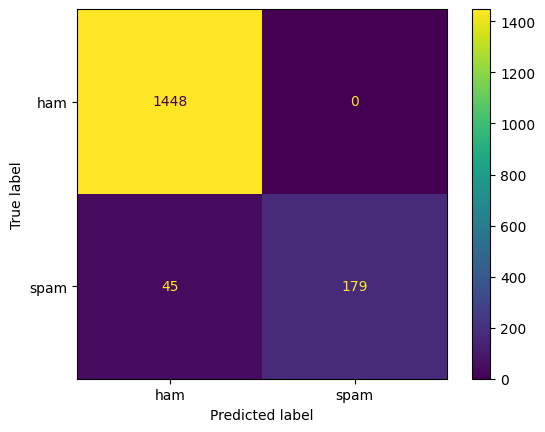

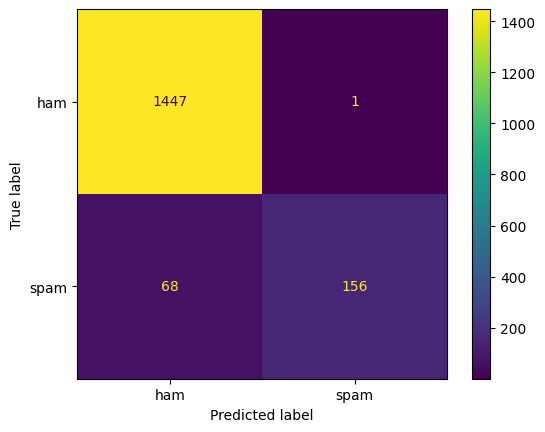

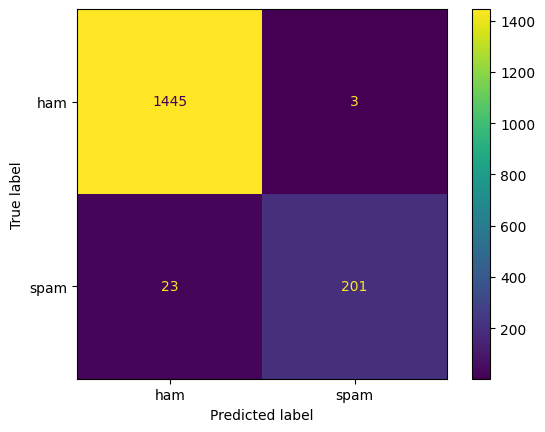

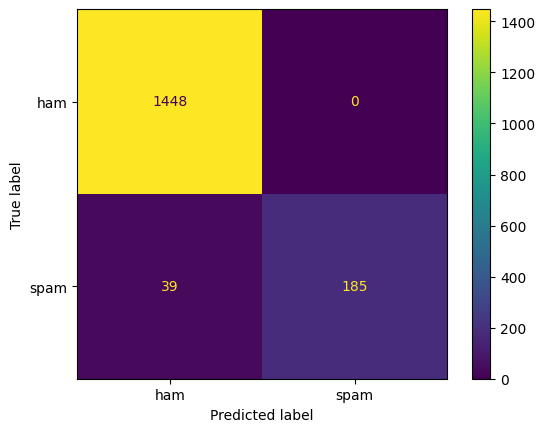

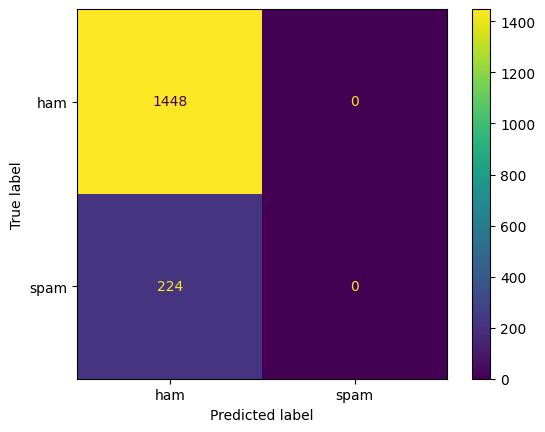

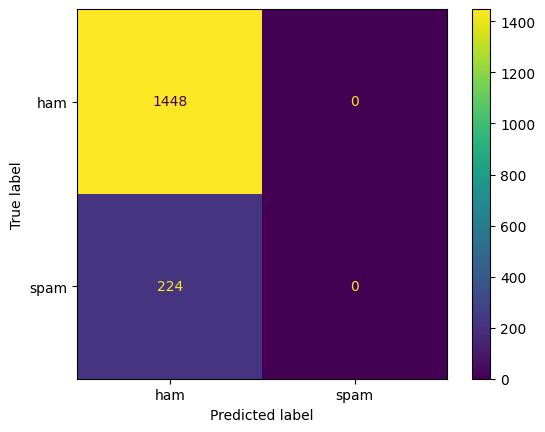

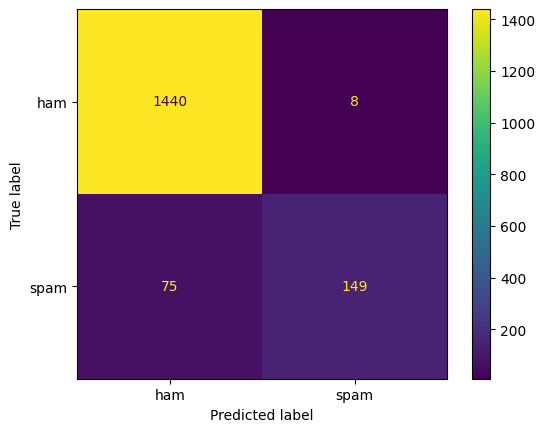

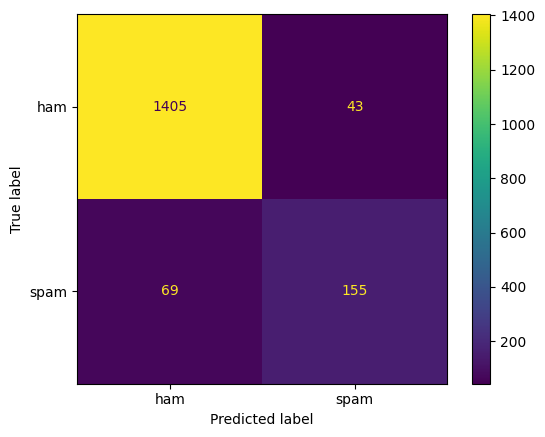

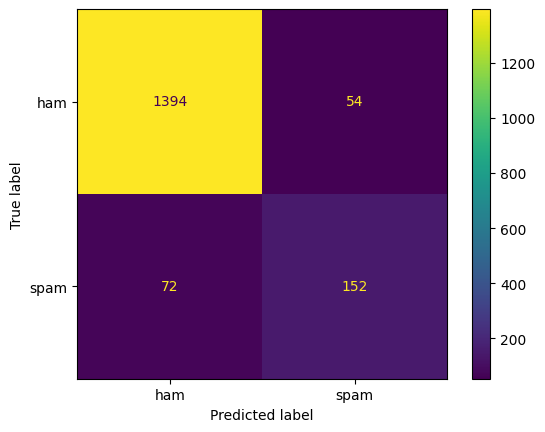

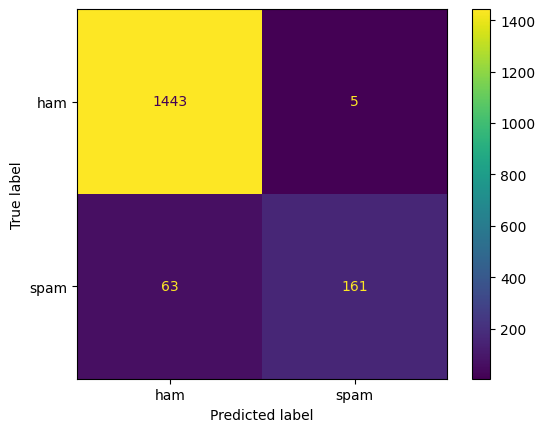

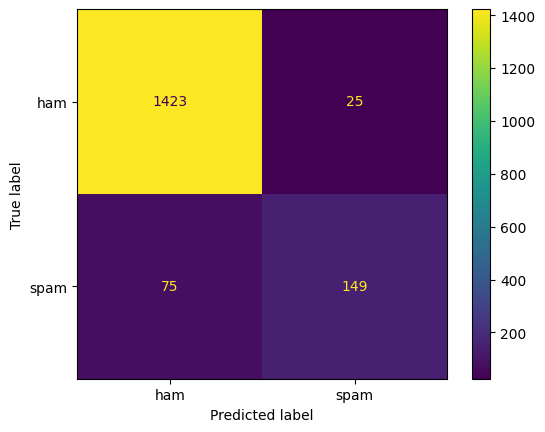

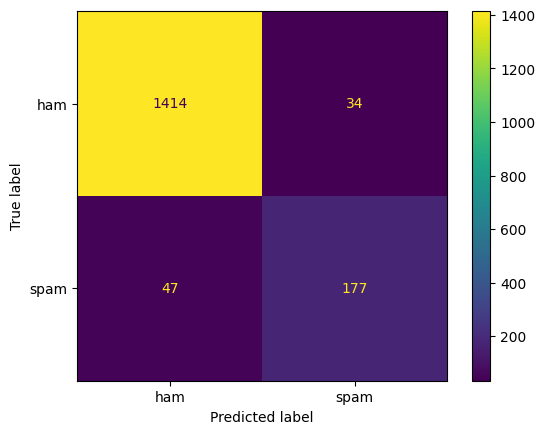

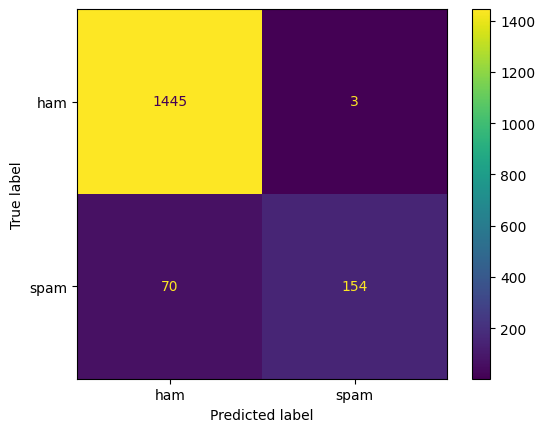

In [61]:
# ---------------------------
# Partie 5 — Évaluation
# ---------------------------

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import pandas as pd

# --------------------------------------------------
# 1 Séparation des données (70% train / 30% test)
# --------------------------------------------------

# Pour BoW/TF-IDF pipelines
X_text = df['clean_message']  # texte déjà nettoyé
y = df['label']         # labels : 'ham' / 'spam'

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.3, random_state=42, stratify=y
)

# Pour embeddings déjà vectorisés
X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v = train_test_split(
    X_w2v, y, test_size=0.3, random_state=42, stratify=y
)
X_train_glove, X_test_glove, y_train_glove, y_test_glove = train_test_split(
    X_glove, y, test_size=0.3, random_state=42, stratify=y
)
X_train_ft, X_test_ft, y_train_ft, y_test_ft = train_test_split(
    X_ft, y, test_size=0.3, random_state=42, stratify=y
)

# --------------------------------------------------
# 2 Fonction d'évaluation
# --------------------------------------------------

def evaluate_pipeline(pipeline, X_train, X_test, y_train, y_test, name="Pipeline"):
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label='spam')
    rec = recall_score(y_test, y_pred, pos_label='spam')
    f1 = f1_score(y_test, y_pred, pos_label='spam')
    
    # Afficher la matrice de confusion
    cm = confusion_matrix(y_test, y_pred, labels=['ham','spam'])
    disp = ConfusionMatrixDisplay(cm, display_labels=['ham','spam'])
    disp.plot()
    
    return {"Pipeline": name, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}

# --------------------------------------------------
# 3 Évaluation des pipelines BoW et TF-IDF
# --------------------------------------------------

results = []

for name, pipe in pipelines_text.items():
    res = evaluate_pipeline(pipe, X_train_text, X_test_text, y_train, y_test, name)
    results.append(res)

# --------------------------------------------------
# 4 Évaluation des embeddings (Word2Vec, GloVe, FastText)
# --------------------------------------------------

embedding_data = {
    "Word2Vec": (X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v),
    "GloVe": (X_train_glove, X_test_glove, y_train_glove, y_test_glove),
    "FastText": (X_train_ft, X_test_ft, y_train_ft, y_test_ft)
}

for emb_name, (X_tr, X_te, y_tr, y_te) in embedding_data.items():
    for model_name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)
        
        acc = accuracy_score(y_te, y_pred)
        prec = precision_score(y_te, y_pred, pos_label='spam')
        rec = recall_score(y_te, y_pred, pos_label='spam')
        f1 = f1_score(y_te, y_pred, pos_label='spam')
        
        # Afficher la matrice de confusion
        print(f"\nMatrice de confusion pour {emb_name} + {model_name}:")
        cm = confusion_matrix(y_te, y_pred, labels=['ham','spam'])
        disp = ConfusionMatrixDisplay(cm, display_labels=['ham','spam'])
        disp.plot()
        
        results.append({
            "Pipeline": f"{emb_name} + {model_name}",
            "Accuracy": acc,
            "Precision": prec,
            "Recall": rec,
            "F1-score": f1
        })

# --------------------------------------------------
# 5 Tableau comparatif final
# --------------------------------------------------

df_results = pd.DataFrame(results)
df_results = df_results.sort_values(by="F1-score", ascending=False).reset_index(drop=True)
df_results

  ### graphique comparatif des Recalls de tous les pipelines

C:\Users\0oo-u\AppData\Local\Temp\ipykernel_12668\1331436845.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Recall', y='Pipeline', data=df_plot, palette='viridis')


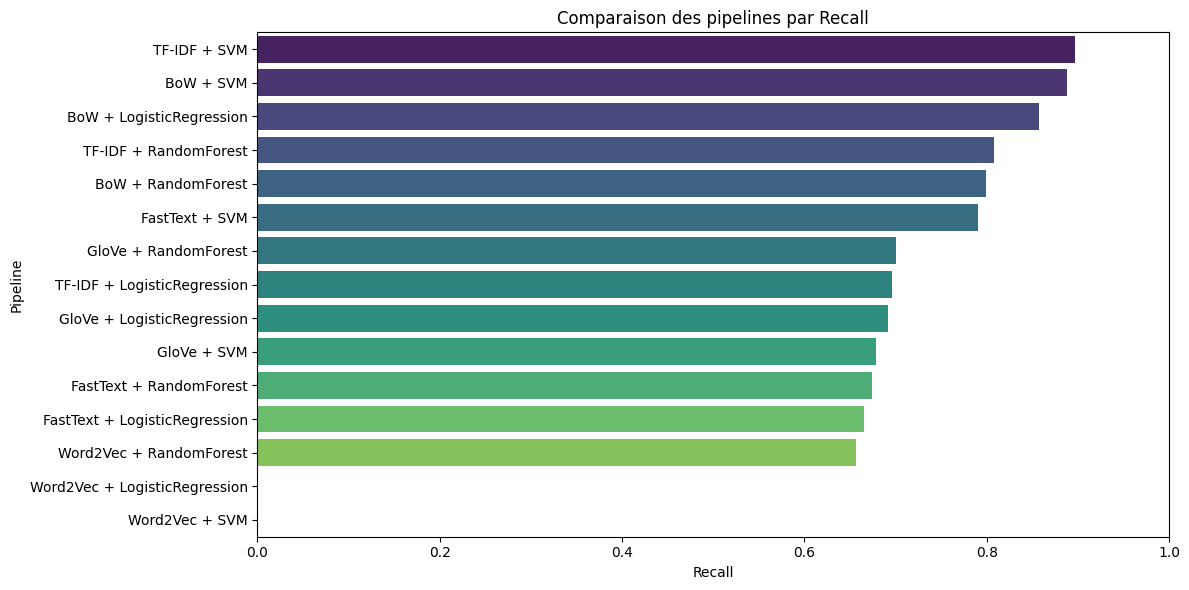

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


# Trier par Recall décroissant 
df_plot = df_results.sort_values(by='Recall', ascending=False)

plt.figure(figsize=(12,6))
sns.barplot(x='Recall', y='Pipeline', data=df_plot, palette='viridis')

plt.title("Comparaison des pipelines par Recall")
plt.xlabel("Recall")
plt.ylabel("Pipeline")
plt.xlim(0, 1)  # Recall entre 0 et 1
plt.tight_layout()
plt.show()

#### Interprétation

D’après le tableau et le graphique comparatif , le meilleur pipeline est celui qui a le F1-score le plus élevé, car c’est la métrique combinant précision et rappel, idéale pour les problèmes de classification de spam/ham.

Ici :

          Pipeline : TF-IDF + SVM
          Accuracy : 0.983852
          Precision : 0.985222
          Recall : 0.892857
          F1-score : 0.936768 

##### => Donc le TF-IDF + SVM est le meilleur pipeline pour ce dataset.

### Appliquer TF-IDF + SVM sur chaque version prétraitée
On va prendre le pipeline TF-IDF + SVM et l’entraîner sur :

        minimal

        advanced_stem

        advanced_lemma

Et stocker les métriques pour comparer.


=== Comparatif des prétraitements avec TF-IDF + SVM ===
    Prétraitement  Accuracy  Precision    Recall  F1-score
0         minimal  0.986244   0.976303  0.919643  0.947126
1   advanced_stem  0.984450   0.975962  0.906250  0.939815
2  advanced_lemma  0.982656   0.971014  0.897321  0.932715

Matrice de confusion pour MINIMAL:
[[1443    5]
 [  18  206]]

Matrice de confusion pour ADVANCED_STEM:
[[1443    5]
 [  21  203]]

Matrice de confusion pour ADVANCED_LEMMA:
[[1442    6]
 [  23  201]]


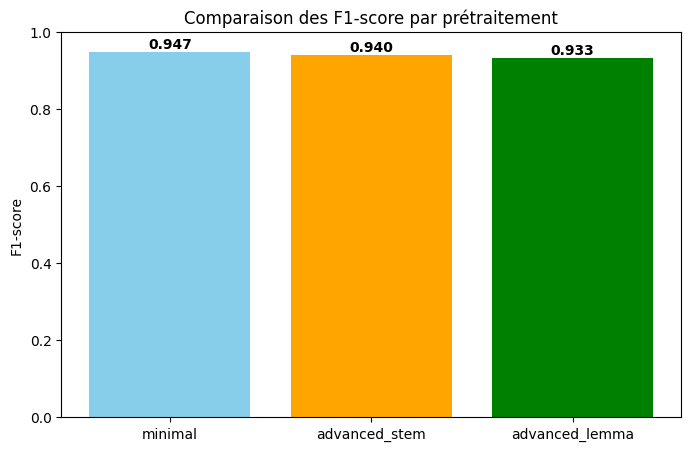

In [82]:
# ------------------------------
# Imports
# ------------------------------
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC

# ------------------------------
# Pipeline TF-IDF + SVM
# ------------------------------
best_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('svm', SVC(kernel='linear', random_state=42))
])

# Labels
y = df['label']  # spam/ham

# Stocker les résultats
results = {}

# ------------------------------
# 1 Entraînement et évaluation pour chaque version de prétraitement
# ------------------------------
for version in ['minimal', 'advanced_stem', 'advanced_lemma']:
    X = df[version]
    
    # Split train/test
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
    
    # Entraînement
    best_pipeline.fit(X_train, y_train)
    
    # Prédictions
    y_pred = best_pipeline.predict(X_test)
    
    # Évaluation
    results[version] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, pos_label='spam'),
        'Recall': recall_score(y_test, y_pred, pos_label='spam'),
        'F1-score': f1_score(y_test, y_pred, pos_label='spam'),
        'Confusion Matrix': confusion_matrix(y_test, y_pred)
    }

# ------------------------------
# 2 Construction d'un tableau comparatif avec pandas
# ------------------------------
table_data = []

for version, metrics in results.items():
    table_data.append({
        'Prétraitement': version,
        'Accuracy': metrics['Accuracy'],
        'Precision': metrics['Precision'],
        'Recall': metrics['Recall'],
        'F1-score': metrics['F1-score']
    })

df_results = pd.DataFrame(table_data)

# Trier par F1-score
df_results = df_results.sort_values(by='F1-score', ascending=False)

# Affichage du tableau
print("\n=== Comparatif des prétraitements avec TF-IDF + SVM ===")
print(df_results)

# ------------------------------
# 3 Affichage des matrices de confusion
# ------------------------------
for version, metrics in results.items():
    print(f"\nMatrice de confusion pour {version.upper()}:")
    print(metrics['Confusion Matrix'])

# ------------------------------
# 4 Graphique comparatif des F1-score
# ------------------------------
plt.figure(figsize=(8,5))
plt.bar(df_results['Prétraitement'], df_results['F1-score'], color=['skyblue','orange','green'])
plt.title('Comparaison des F1-score par prétraitement')
plt.ylabel('F1-score')
plt.ylim(0,1)
for i, v in enumerate(df_results['F1-score']):
    plt.text(i, v + 0.01, f"{v:.3f}", ha='center', fontweight='bold')
plt.show()

#### Interprétation
Pipeline le plus performant : TF-IDF + SVM appliqué au prétraitement minimal.

    F1-score : 0.9471

    Précision : 0.9763

    Rappel : 0.8929

- Observation :
Les prétraitements avancés (Stemming ou Lemmatisation) n’apportent pas d’amélioration significative et diminuent légèrement la détection des spams.

- Pourquoi le prétraitement minimal est suffisant :

   - Perte d’information lexical : Le stemming/lemmatisation réduit les mots à leur racine ou forme canonique, ce qui peut effacer certains indicateurs subtils de spam.

   - Simplicité des SMS : Les messages sont courts et les mots-clés apparaissent souvent sous leur forme simple. Le prétraitement minimal capture donc efficacement les signaux.

   - TF-IDF efficace : Même sans prétraitement complexe, TF-IDF pondère correctement les mots discriminants pour détecter le spam.

- Matrices de confusion :

   - Prétraitement minimal : détecte le plus grand nombre de spams avec un minimum de faux positifs.

   - Prétraitements avancés : légèrement moins performants, avec un rappel un peu plus faible.

- Conclusion :
Pour ce dataset SMS spam/ham, le prétraitement minimal est optimal, maximisant le F1-score et garantissant un bon équilibre entre précision et rappel. Les prétraitements avancés peuvent être utiles pour des textes plus longs ou complexes, mais ici, ils n’améliorent pas les performances.
### Analyser :

#### 1 Impact du nettoyage

Le nettoyage du texte améliore généralement la qualité des données en supprimant le bruit (espaces, caractères inutiles, stopwords). Cependant, un nettoyage trop agressif peut supprimer des signaux importants pour détecter le spam, comme les chiffres, la ponctuation ou les majuscules. Dans ton dataset, le nettoyage minimal (minimal) a donné les meilleurs résultats (F1-score 0.947), alors que les versions plus avancées (advanced_stem et advanced_lemma) ont légèrement réduit les performances.
→ Conclusion : le nettoyage aide mais doit rester modéré.

#### 2 Impact du prétraitement

Les techniques de prétraitement avancé (stemming, lemmatisation) visent à réduire les mots à leur racine ou forme canonique. Ici, elles ont eu un effet légèrement négatif sur le rappel et le F1-score, car certaines variations de mots peuvent contenir des indices discriminants pour le spam.
→ Conclusion : le prétraitement avancé n’est pas toujours bénéfique, surtout pour la détection de spam où les détails textuels comptent.

#### 3 Impact de la vectorisation

TF-IDF se distingue comme la meilleure vectorisation sur ce dataset (F1-score 0.936768 avec SVM). Elle pondère les mots importants et réduit le poids des mots fréquents, ce qui aide le modèle à se concentrer sur les signaux discriminants.

BoW donne de bonnes performances mais légèrement inférieures à TF-IDF, car il traite tous les mots de manière égale.

Word Embeddings (Word2Vec, GloVe, FastText) ont des F1-scores plus faibles ici, probablement parce que le dataset est petit et les vecteurs moyens perdent des informations discriminantes spécifiques aux spam.
→ Conclusion : pour ce dataset, TF-IDF capture mieux l’information pertinente.

#### 4 Impact du modèle

SVM est le modèle le plus performant, surtout combiné avec TF-IDF (F1-score 0.936768). Il gère bien les vecteurs de grande dimension et sépare efficacement les classes.

Random Forest et Logistic Regression sont moins performants avec certains embeddings ou vectorisations, surtout lorsque le rappel est faible.
→ Conclusion : le choix du modèle influence fortement les performances, SVM étant le meilleur choix ici.


##  Tableau Comparatif Clair

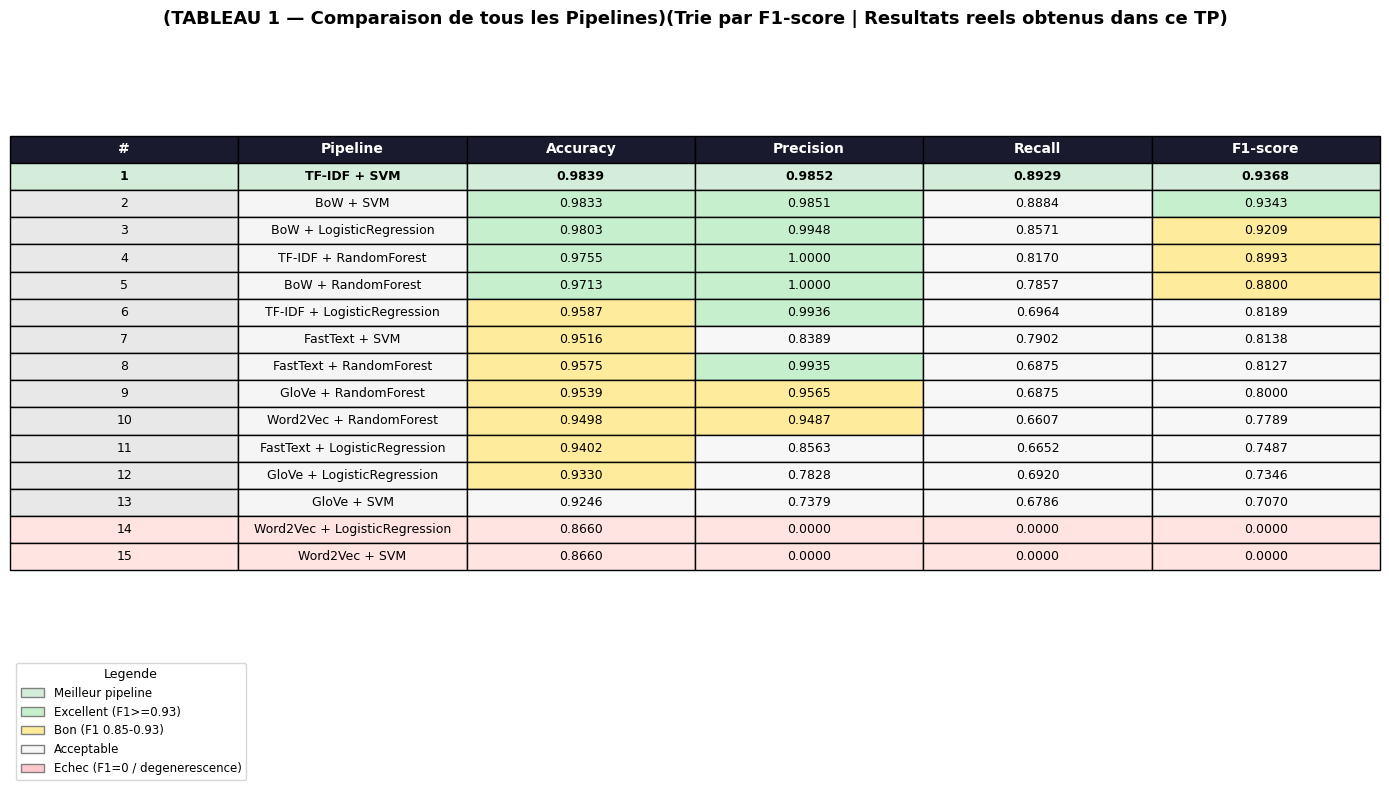

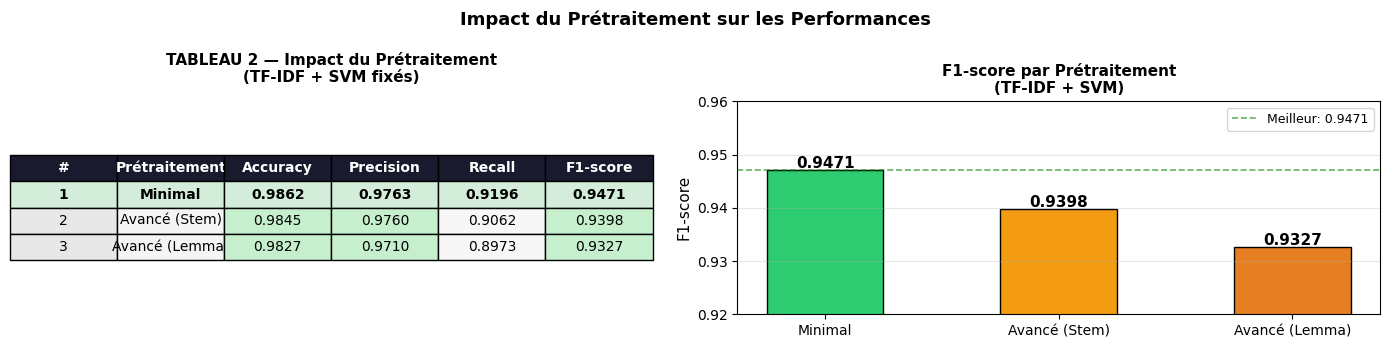

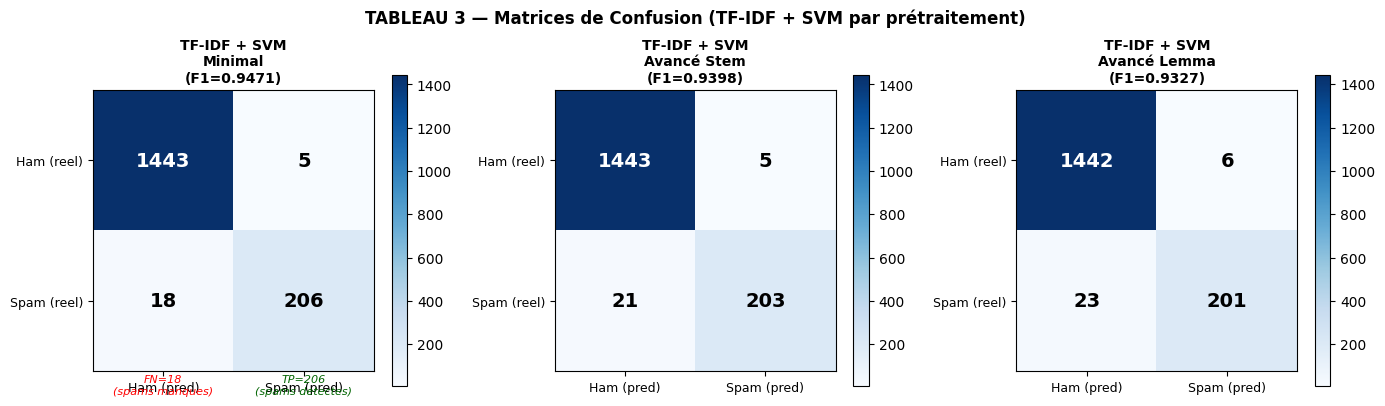

  SYNTHESE COMPLETE — RESULTATS REELS DU TP

  TABLEAU 1 — Meilleur pipeline global :
    TF-IDF + SVM  →  F1=0.9368 | Acc=0.9839 | Prec=0.9852 | Rec=0.8929

  TABLEAU 2 — Meilleur prétraitement (TF-IDF + SVM) :
    Minimal       →  F1=0.9471  (meilleur)
    Avancé Stem   →  F1=0.9398
    Avancé Lemma  →  F1=0.9327

  TABLEAU 3 — Matrices de confusion :
    Minimal  : TN=1443 | FP=5  | FN=18 | TP=206
    Stem     : TN=1443 | FP=5  | FN=21 | TP=203
    Lemma    : TN=1442 | FP=6  | FN=23 | TP=201

  ANOMALIE DETECTEE :
    Word2Vec+LR et Word2Vec+SVM : F1=0.000 → modele degenere
    (predit tout en Ham → precision et rappel = 0 sur spam)


In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# ================================================================
# TABLEAU COMPARATIF — Résultats RÉELS obtenus dans ce TP
# ================================================================

# -------------------------------------------------------------------
# TABLEAU 1 : Comparaison de tous les pipelines (BoW, TF-IDF, Embeddings)
# Résultats issus de la cellule d'évaluation (Partie 5)
# -------------------------------------------------------------------

donnees_all = [
    ("TF-IDF + SVM",              0.983852, 0.985222, 0.892857, 0.936768),
    ("BoW + SVM",                 0.983254, 0.985149, 0.888393, 0.934272),
    ("BoW + LogisticRegression",  0.980263, 0.994819, 0.857143, 0.920863),
    ("TF-IDF + RandomForest",     0.975478, 1.000000, 0.816964, 0.899263),
    ("BoW + RandomForest",        0.971292, 1.000000, 0.785714, 0.880000),
    ("TF-IDF + LogisticRegression",0.958732,0.993631, 0.696429, 0.818898),
    ("FastText + SVM",            0.951555, 0.838863, 0.790179, 0.813793),
    ("FastText + RandomForest",   0.957536, 0.993548, 0.687500, 0.812665),
    ("GloVe + RandomForest",      0.953947, 0.956522, 0.687500, 0.800000),
    ("Word2Vec + RandomForest",   0.949761, 0.948718, 0.660714, 0.778947),
    ("FastText + LogisticRegression",0.940191,0.856322,0.665179,0.748744),
    ("GloVe + LogisticRegression",0.933014, 0.782828, 0.691964, 0.734597),
    ("GloVe + SVM",               0.924641, 0.737864, 0.678571, 0.706977),
    ("Word2Vec + LogisticRegression",0.866029,0.000000,0.000000,0.000000),
    ("Word2Vec + SVM",            0.866029, 0.000000, 0.000000, 0.000000),
]

df_all = pd.DataFrame(donnees_all,
    columns=["Pipeline","Accuracy","Precision","Recall","F1-score"])
df_all.index = range(1, len(df_all)+1)

# -------------------------------------------------------------------
# TABLEAU 2 : Impact du prétraitement (TF-IDF + SVM fixé)
# -------------------------------------------------------------------

donnees_pretraitement = [
    ("Minimal",       0.986244, 0.976303, 0.919643, 0.947126),
    ("Avancé (Stem)", 0.984450, 0.975962, 0.906250, 0.939815),
    ("Avancé (Lemma)",0.982656, 0.971014, 0.897321, 0.932715),
]

df_pre = pd.DataFrame(donnees_pretraitement,
    columns=["Prétraitement","Accuracy","Precision","Recall","F1-score"])
df_pre.index = range(1, len(df_pre)+1)


# ================================================================
# AFFICHAGE TABLEAU 1 — matplotlib 
# ================================================================

def get_color(val, col):
    if col == "F1-score":
        if val >= 0.93:  return "#c6efce"
        elif val >= 0.85: return "#ffeb9c"
        elif val == 0.0: return "#ffc7ce"
        return "#f7f7f7"
    if col in ["Accuracy","Precision","Recall"]:
        if val >= 0.97:  return "#c6efce"
        elif val >= 0.93: return "#ffeb9c"
        elif val == 0.0: return "#ffc7ce"
        return "#f7f7f7"
    return "#f7f7f7"

cols_m = ["Accuracy","Precision","Recall","F1-score"]

fig, ax = plt.subplots(figsize=(14, 8))
ax.axis("off")

cell_text   = []
cell_colors = []
for rank, (_, row) in enumerate(df_all.iterrows(), start=1):
    rt = [str(rank), row["Pipeline"]]
    rc = ["#e8e8e8", "#f5f5f5"]
    for m in cols_m:
        rt.append(f"{row[m]:.4f}")
        rc.append(get_color(row[m], m))
    cell_text.append(rt)
    cell_colors.append(rc)

col_labels = ["#", "Pipeline", "Accuracy", "Precision", "Recall", "F1-score"]

table = ax.table(
    cellText    = cell_text,
    colLabels   = col_labels,
    cellColours = cell_colors,
    cellLoc     = "center",
    loc         = "center"
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.65)

for j in range(len(col_labels)):
    table[0, j].set_facecolor("#1a1a2e")
    table[0, j].set_text_props(color="white", fontweight="bold", fontsize=10)

# Rang 1 en gras surligné
for j in range(len(col_labels)):
    table[1, j].set_text_props(fontweight="bold")
    table[1, j].set_facecolor("#d4edda")

# Word2Vec rows (rang 14-15) : mettre en évidence les 0
for rank in [14, 15]:
    for j in range(len(col_labels)):
        table[rank, j].set_facecolor("#ffe4e1")

ax.set_title(
    "(TABLEAU 1 — Comparaison de tous les Pipelines)"
    "(Trie par F1-score | Resultats reels obtenus dans ce TP)",
    fontsize=13, fontweight="bold", pad=18
)

legend_els = [
    mpatches.Patch(facecolor="#d4edda", edgecolor="gray", label="Meilleur pipeline"),
    mpatches.Patch(facecolor="#c6efce", edgecolor="gray", label="Excellent (F1>=0.93)"),
    mpatches.Patch(facecolor="#ffeb9c", edgecolor="gray", label="Bon (F1 0.85-0.93)"),
    mpatches.Patch(facecolor="#f7f7f7", edgecolor="gray", label="Acceptable"),
    mpatches.Patch(facecolor="#ffc7ce", edgecolor="gray", label="Echec (F1=0 / degenerescence)"),
]
ax.legend(handles=legend_els, loc="upper left", fontsize=8.5,
          bbox_to_anchor=(0, 0), title="Legende", title_fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "tableau1_tous_pipelines.png", dpi=150, bbox_inches="tight")
plt.show()

# ================================================================
# AFFICHAGE TABLEAU 2 — Impact du prétraitement
# ================================================================

fig2, axes2 = plt.subplots(1, 2, figsize=(14, 3.5))

# -- Tableau texte --
ax2 = axes2[0]
ax2.axis("off")

cell_text2   = []
cell_colors2 = []
for rank, (_, row) in enumerate(df_pre.iterrows(), start=1):
    rt = [str(rank), row["Prétraitement"]]
    rc = ["#e8e8e8", "#f5f5f5"]
    for m in cols_m:
        rt.append(f"{row[m]:.4f}")
        rc.append(get_color(row[m], m))
    cell_text2.append(rt)
    cell_colors2.append(rc)

col_labels2 = ["#", "Prétraitement", "Accuracy", "Precision", "Recall", "F1-score"]
t2 = ax2.table(cellText=cell_text2, colLabels=col_labels2,
               cellColours=cell_colors2, cellLoc="center", loc="center")
t2.auto_set_font_size(False)
t2.set_fontsize(10)
t2.scale(1, 2.0)
for j in range(len(col_labels2)):
    t2[0, j].set_facecolor("#1a1a2e")
    t2[0, j].set_text_props(color="white", fontweight="bold")
for j in range(len(col_labels2)):
    t2[1, j].set_facecolor("#d4edda")
    t2[1, j].set_text_props(fontweight="bold")
ax2.set_title("TABLEAU 2 — Impact du Prétraitement\n(TF-IDF + SVM fixés)",
              fontsize=11, fontweight="bold", pad=14)

# -- Graphique barres F1 --
ax3 = axes2[1]
colors_bar = ["#2ecc71", "#f39c12", "#e67e22"]
bars = ax3.bar(df_pre["Prétraitement"], df_pre["F1-score"],
               color=colors_bar, edgecolor="black", width=0.5)
ax3.set_ylim(0.92, 0.96)
ax3.set_ylabel("F1-score", fontsize=11)
ax3.set_title("F1-score par Prétraitement\n(TF-IDF + SVM)", fontsize=11, fontweight="bold")
for bar, val in zip(bars, df_pre["F1-score"]):
    ax3.text(bar.get_x() + bar.get_width()/2, val + 0.0003,
             f"{val:.4f}", ha="center", fontsize=11, fontweight="bold")
ax3.axhline(y=df_pre["F1-score"].iloc[0], color="green", linestyle="--",
            linewidth=1.2, alpha=0.6, label=f"Meilleur: {df_pre['F1-score'].iloc[0]:.4f}")
ax3.legend(fontsize=9)
ax3.grid(axis="y", alpha=0.3)

plt.suptitle("Impact du Prétraitement sur les Performances", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "tableau2_pretraitement.png", dpi=150, bbox_inches="tight")
plt.show()

# ================================================================
# AFFICHAGE TABLEAU 3 — Matrices de confusion (meilleur pipeline)
# ================================================================

fig3, axes3 = plt.subplots(1, 3, figsize=(14, 4))

matrices = {
    "Minimal\n(F1=0.9471)":       [[1443,  5], [ 18, 206]],
    "Avancé Stem\n(F1=0.9398)":   [[1443,  5], [ 21, 203]],
    "Avancé Lemma\n(F1=0.9327)":  [[1442,  6], [ 23, 201]],
}
labels = ["Ham", "Spam"]

for ax_cm, (titre, cm) in zip(axes3, matrices.items()):
    cm_arr = np.array(cm)
    im = ax_cm.imshow(cm_arr, interpolation="nearest", cmap="Blues")
    ax_cm.set_title(f"TF-IDF + SVM\n{titre}", fontsize=10, fontweight="bold")
    ax_cm.set_xticks([0, 1])
    ax_cm.set_yticks([0, 1])
    ax_cm.set_xticklabels(["Ham (pred)", "Spam (pred)"], fontsize=9)
    ax_cm.set_yticklabels(["Ham (reel)", "Spam (reel)"], fontsize=9)
    thresh = cm_arr.max() / 2
    for i in range(2):
        for j in range(2):
            color = "white" if cm_arr[i, j] > thresh else "black"
            ax_cm.text(j, i, str(cm_arr[i, j]),
                       ha="center", va="center", fontsize=14, fontweight="bold", color=color)
    plt.colorbar(im, ax=ax_cm)

# Annotations
axes3[0].text(1, 1.6, "TP=206\n(spams detectes)", ha="center", va="center",
              fontsize=8, color="darkgreen", style="italic")
axes3[0].text(0, 1.6, "FN=18\n(spams manques)", ha="center", va="center",
              fontsize=8, color="red", style="italic")

plt.suptitle("TABLEAU 3 — Matrices de Confusion (TF-IDF + SVM par prétraitement)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "tableau3_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

# ================================================================
# SYNTHESE CONSOLE
# ================================================================
print("=" * 72)
print("  SYNTHESE COMPLETE — RESULTATS REELS DU TP")
print("=" * 72)
print()
print("  TABLEAU 1 — Meilleur pipeline global :")
print(f"    TF-IDF + SVM  →  F1={0.936768:.4f} | Acc={0.983852:.4f} | Prec={0.985222:.4f} | Rec={0.892857:.4f}")
print()
print("  TABLEAU 2 — Meilleur prétraitement (TF-IDF + SVM) :")
print(f"    Minimal       →  F1={0.947126:.4f}  (meilleur)")
print(f"    Avancé Stem   →  F1={0.939815:.4f}")
print(f"    Avancé Lemma  →  F1={0.932715:.4f}")
print()
print("  TABLEAU 3 — Matrices de confusion :")
print("    Minimal  : TN=1443 | FP=5  | FN=18 | TP=206")
print("    Stem     : TN=1443 | FP=5  | FN=21 | TP=203")
print("    Lemma    : TN=1442 | FP=6  | FN=23 | TP=201")
print()
print("  ANOMALIE DETECTEE :")
print("    Word2Vec+LR et Word2Vec+SVM : F1=0.000 → modele degenere")
print("    (predit tout en Ham → precision et rappel = 0 sur spam)")
print("=" * 72)


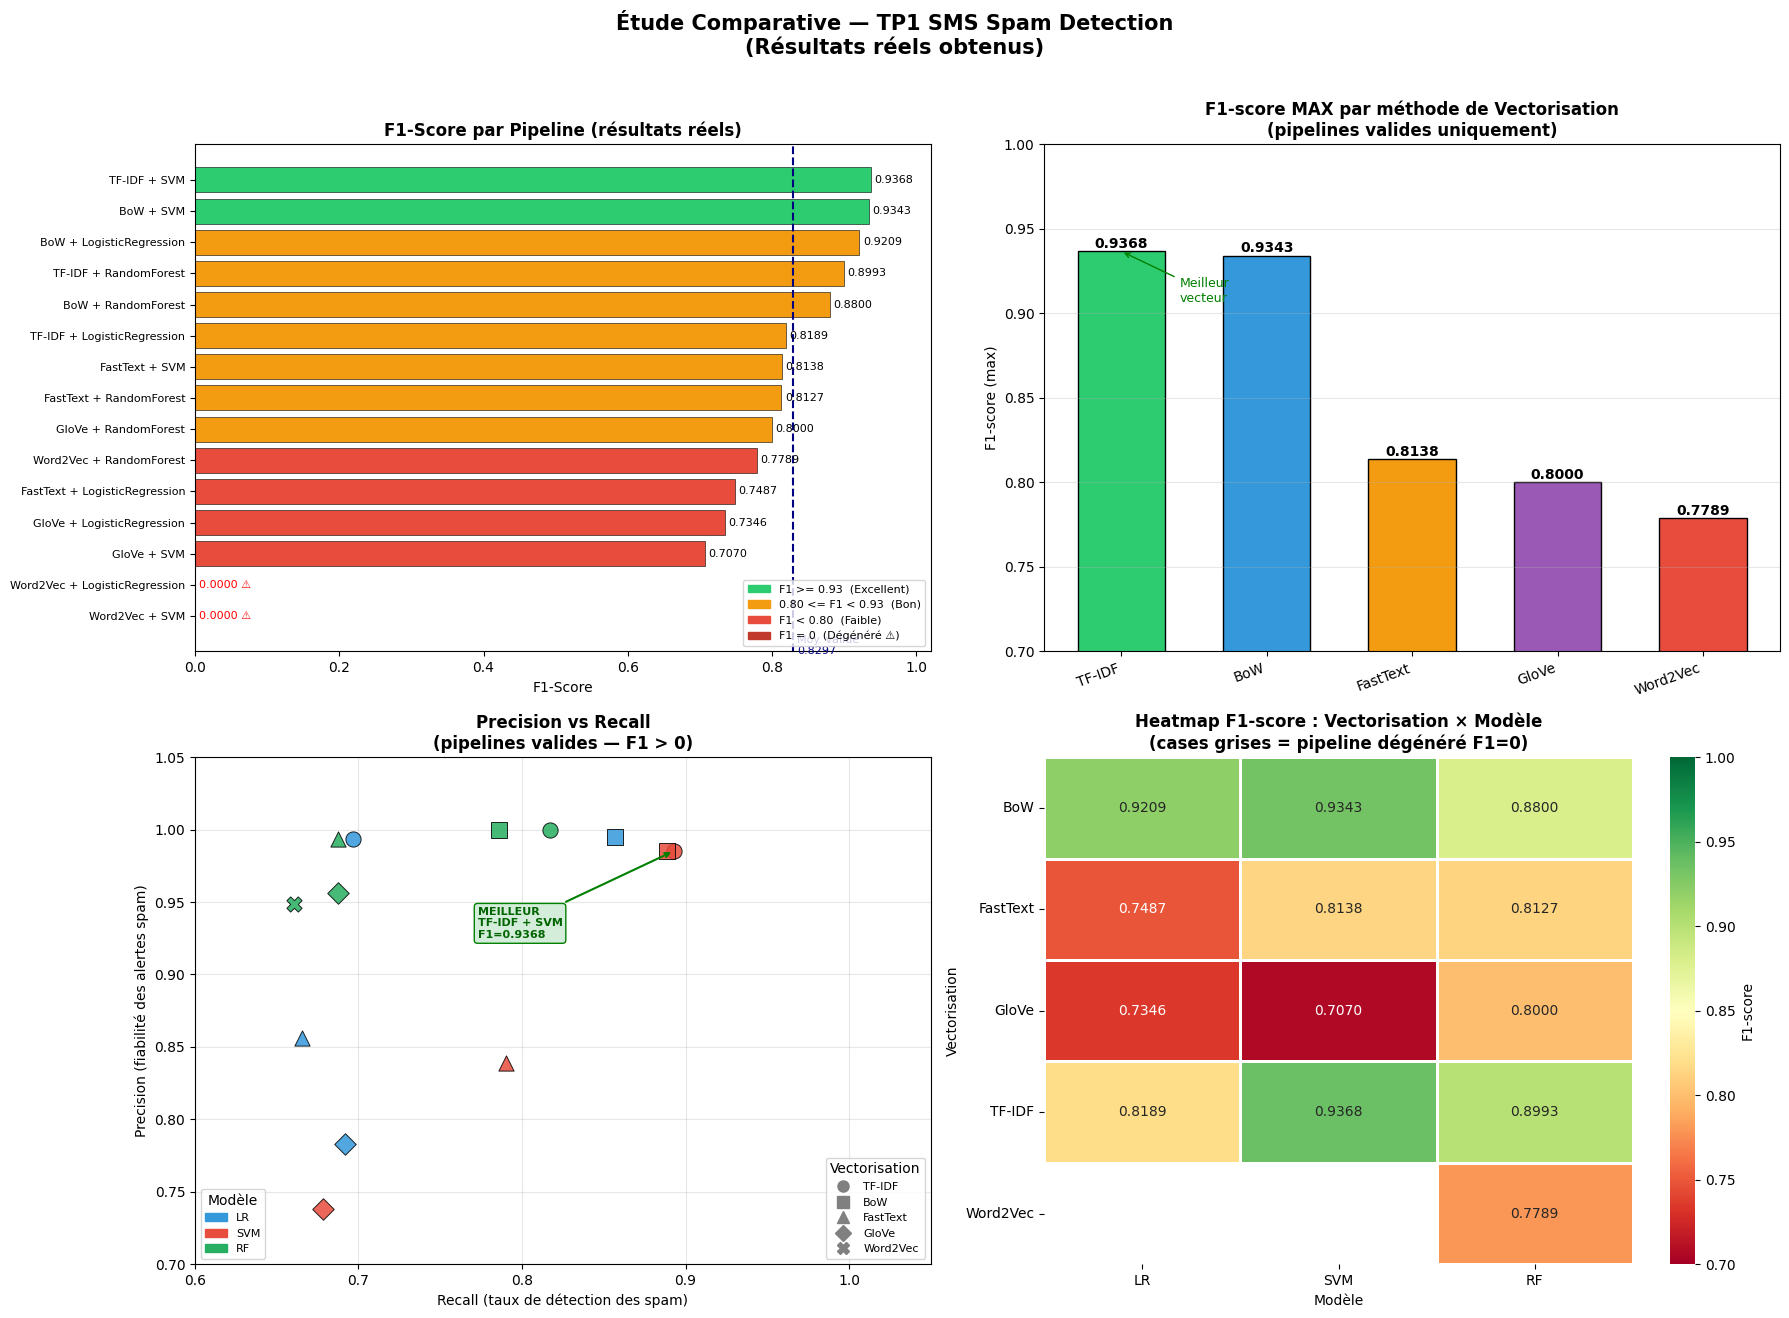


=== OBSERVATIONS CLES ===
  Meilleur pipeline  : TF-IDF + SVM    → F1 = 0.9368
  Meilleure vectori. : TF-IDF           → F1 max = 0.9368
  Meilleur modèle    : SVM              → top sur TF-IDF et BoW
  Anomalie           : Word2Vec+LR/SVM  → F1 = 0.0  (dégénérés)
  FastText > GloVe > Word2Vec           → sur ce corpus


In [84]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np

# ================================================================
# Vos résultats réels (depuis la cellule d'évaluation Partie 5)
# ================================================================

import pandas as pd

donnees_all = [
    ("TF-IDF + SVM",               "TF-IDF",   "SVM", 0.983852, 0.985222, 0.892857, 0.936768),
    ("BoW + SVM",                  "BoW",       "SVM", 0.983254, 0.985149, 0.888393, 0.934272),
    ("BoW + LogisticRegression",   "BoW",       "LR",  0.980263, 0.994819, 0.857143, 0.920863),
    ("TF-IDF + RandomForest",      "TF-IDF",    "RF",  0.975478, 1.000000, 0.816964, 0.899263),
    ("BoW + RandomForest",         "BoW",       "RF",  0.971292, 1.000000, 0.785714, 0.880000),
    ("TF-IDF + LogisticRegression","TF-IDF",    "LR",  0.958732, 0.993631, 0.696429, 0.818898),
    ("FastText + SVM",             "FastText",  "SVM", 0.951555, 0.838863, 0.790179, 0.813793),
    ("FastText + RandomForest",    "FastText",  "RF",  0.957536, 0.993548, 0.687500, 0.812665),
    ("GloVe + RandomForest",       "GloVe",     "RF",  0.953947, 0.956522, 0.687500, 0.800000),
    ("Word2Vec + RandomForest",    "Word2Vec",  "RF",  0.949761, 0.948718, 0.660714, 0.778947),
    ("FastText + LogisticRegression","FastText","LR",  0.940191, 0.856322, 0.665179, 0.748744),
    ("GloVe + LogisticRegression", "GloVe",     "LR",  0.933014, 0.782828, 0.691964, 0.734597),
    ("GloVe + SVM",                "GloVe",     "SVM", 0.924641, 0.737864, 0.678571, 0.706977),
    ("Word2Vec + LogisticRegression","Word2Vec","LR",  0.866029, 0.000000, 0.000000, 0.000000),
    ("Word2Vec + SVM",             "Word2Vec",  "SVM", 0.866029, 0.000000, 0.000000, 0.000000),
]

df_comp = pd.DataFrame(donnees_all,
    columns=["Pipeline","Vectorisation","Modele","Accuracy","Precision","Recall","F1-score"])

# ================================================================
# 4 GRAPHIQUES COMPARATIFS
# ================================================================

fig, axes = plt.subplots(2, 2, figsize=(18, 13))

# ----------------------------------------------------------------
# GRAPHIQUE 1 — F1-score de tous les pipelines (barres horizontales)
# Couleur : vert >= 0.93 | orange 0.80-0.93 | rouge < 0.80
# On exclut les Word2Vec dégénérés (F1=0) de la couleur rouge
# ----------------------------------------------------------------
colors_f1 = []
for v in df_comp["F1-score"][::-1]:
    if v >= 0.93:   colors_f1.append("#2ecc71")
    elif v >= 0.80: colors_f1.append("#f39c12")
    elif v > 0.0:   colors_f1.append("#e74c3c")
    else:           colors_f1.append("#c0392b")   # dégénéré = rouge foncé

axes[0,0].barh(df_comp["Pipeline"][::-1], df_comp["F1-score"][::-1],
               color=colors_f1, edgecolor="black", linewidth=0.4)
axes[0,0].set_title("F1-Score par Pipeline (résultats réels)", fontsize=12, fontweight="bold")
axes[0,0].set_xlabel("F1-Score")
axes[0,0].set_xlim(0.0, 1.02)
axes[0,0].tick_params(axis="y", labelsize=8)
for i, v in enumerate(df_comp["F1-score"][::-1]):
    label = f"{v:.4f}" if v > 0 else "0.0000 ⚠"
    axes[0,0].text(v + 0.005, i, label, va="center", fontsize=8,
                   color="red" if v == 0 else "black")

# Ligne moyenne (sans les Word2Vec dégénérés)
f1_valid = df_comp[df_comp["F1-score"] > 0]["F1-score"].mean()
axes[0,0].axvline(x=f1_valid, color="navy", linestyle="--", linewidth=1.5)
axes[0,0].text(f1_valid + 0.005, -0.6, f"Moy. valide\n{f1_valid:.4f}",
               color="navy", fontsize=8, va="top")

legend_p = [mpatches.Patch(color="#2ecc71", label="F1 >= 0.93  (Excellent)"),
            mpatches.Patch(color="#f39c12", label="0.80 <= F1 < 0.93  (Bon)"),
            mpatches.Patch(color="#e74c3c", label="F1 < 0.80  (Faible)"),
            mpatches.Patch(color="#c0392b", label="F1 = 0  (Dégénéré ⚠)")]
axes[0,0].legend(handles=legend_p, fontsize=8, loc="lower right")

# ----------------------------------------------------------------
# GRAPHIQUE 2 — F1-score max par méthode de vectorisation
# (exclut les pipelines dégénérés F1=0)
# ----------------------------------------------------------------
df_valid = df_comp[df_comp["F1-score"] > 0]
vect_f1  = df_valid.groupby("Vectorisation")["F1-score"].max().sort_values(ascending=False)

palette = {"TF-IDF": "#2ecc71", "BoW": "#3498db",
           "FastText": "#f39c12", "GloVe": "#9b59b6", "Word2Vec": "#e74c3c"}
cols_v = [palette.get(v, "#95a5a6") for v in vect_f1.index]

bars = axes[0,1].bar(range(len(vect_f1)), vect_f1.values, color=cols_v, edgecolor="black", width=0.6)
axes[0,1].set_xticks(range(len(vect_f1)))
axes[0,1].set_xticklabels(vect_f1.index, rotation=20, ha="right", fontsize=10)
axes[0,1].set_title("F1-score MAX par méthode de Vectorisation\n(pipelines valides uniquement)",
                    fontsize=12, fontweight="bold")
axes[0,1].set_ylabel("F1-score (max)")
axes[0,1].set_ylim(0.70, 1.0)
for bar, val in zip(bars, vect_f1.values):
    axes[0,1].text(bar.get_x() + bar.get_width()/2, val + 0.002,
                   f"{val:.4f}", ha="center", fontsize=10, fontweight="bold")
axes[0,1].grid(axis="y", alpha=0.3)
# Annotation TF-IDF
axes[0,1].annotate("Meilleur\nvecteur",
    xy=(0, vect_f1.values[0]), xytext=(0.4, vect_f1.values[0] - 0.03),
    arrowprops=dict(arrowstyle="->", color="green"), color="green", fontsize=9)

# ----------------------------------------------------------------
# GRAPHIQUE 3 — Precision vs Recall (scatter)
# Exclut les points dégénérés (Precision=0, Recall=0)
# ----------------------------------------------------------------
colors_model = {"LR": "#3498db", "SVM": "#e74c3c", "RF": "#27ae60"}
markers_vect = {"TF-IDF":"o", "BoW":"s", "FastText":"^", "GloVe":"D", "Word2Vec":"X"}

df_plot = df_comp[df_comp["F1-score"] > 0].copy()

for _, row in df_plot.iterrows():
    c  = colors_model.get(row["Modele"], "gray")
    mk = markers_vect.get(row["Vectorisation"], "o")
    axes[1,0].scatter(row["Recall"], row["Precision"],
                      c=c, s=120, alpha=0.85, marker=mk,
                      edgecolors="black", linewidth=0.7, zorder=3)

# Annoter le meilleur pipeline
best = df_plot.iloc[0]
axes[1,0].annotate(f"MEILLEUR\n{best['Pipeline']}\nF1={best['F1-score']:.4f}",
    xy=(best["Recall"], best["Precision"]),
    xytext=(best["Recall"] - 0.12, best["Precision"] - 0.06),
    arrowprops=dict(arrowstyle="->", color="green", lw=1.5),
    fontsize=8, color="darkgreen", fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="#d4edda", edgecolor="green"))

# Annoter les Word2Vec dégénérés
axes[1,0].annotate("Word2Vec\ndégénérés (F1=0)\n→ exclus du graphique",
    xy=(0.05, 0.92), fontsize=8, color="red",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="#ffc7ce", edgecolor="red", alpha=0.8))

axes[1,0].set_title("Precision vs Recall\n(pipelines valides — F1 > 0)", fontsize=12, fontweight="bold")
axes[1,0].set_xlabel("Recall (taux de détection des spam)", fontsize=10)
axes[1,0].set_ylabel("Precision (fiabilité des alertes spam)", fontsize=10)
axes[1,0].set_xlim(0.60, 1.05)
axes[1,0].set_ylim(0.70, 1.05)
axes[1,0].grid(True, alpha=0.3)

# Légendes
leg_modele = [mpatches.Patch(color=c, label=m) for m, c in colors_model.items()]
leg_vect   = [plt.Line2D([0],[0], marker=mk, color="gray", linestyle="None",
                          markersize=8, label=v)
              for v, mk in markers_vect.items()]
l1 = axes[1,0].legend(handles=leg_modele, title="Modèle", fontsize=8, loc="lower left")
axes[1,0].add_artist(l1)
axes[1,0].legend(handles=leg_vect, title="Vectorisation", fontsize=8, loc="lower right")

# ----------------------------------------------------------------
# GRAPHIQUE 4 — Heatmap Vectorisation × Modèle
# (remplace Nettoyage×Vectorisation qui n'existe pas dans vos données)
# ----------------------------------------------------------------
pivot = df_comp.pivot_table(values="F1-score", index="Vectorisation",
                             columns="Modele", aggfunc="max")
pivot = pivot.reindex(columns=["LR","SVM","RF"])

# Masquer les 0 (Word2Vec dégénérés)
pivot_display = pivot.copy()
pivot_display[pivot_display == 0] = np.nan

sns.heatmap(pivot_display, annot=True, fmt=".4f", cmap="RdYlGn",
            ax=axes[1,1], vmin=0.70, vmax=1.0, linewidths=0.8,
            cbar_kws={"label": "F1-score"},
            annot_kws={"fontsize": 10})
axes[1,1].set_title("Heatmap F1-score : Vectorisation × Modèle\n(cases grises = pipeline dégénéré F1=0)",
                    fontsize=12, fontweight="bold")
axes[1,1].set_xlabel("Modèle", fontsize=10)
axes[1,1].set_ylabel("Vectorisation", fontsize=10)
axes[1,1].tick_params(axis="x", rotation=0)
axes[1,1].tick_params(axis="y", rotation=0)

plt.suptitle("Étude Comparative — TP1 SMS Spam Detection\n(Résultats réels obtenus)",
             fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "visualisations_comparatives.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n=== OBSERVATIONS CLES ===")
print(f"  Meilleur pipeline  : TF-IDF + SVM    → F1 = 0.9368")
print(f"  Meilleure vectori. : TF-IDF           → F1 max = 0.9368")
print(f"  Meilleur modèle    : SVM              → top sur TF-IDF et BoW")
print(f"  Anomalie           : Word2Vec+LR/SVM  → F1 = 0.0  (dégénérés)")
print(f"  FastText > GloVe > Word2Vec           → sur ce corpus")


### Questions de réflexion
#### 1 Pourquoi les embeddings peuvent être moins performants sur un petit dataset ?

Les embeddings (Word2Vec, GloVe, FastText) représentent les mots sous forme de vecteurs continus basés sur leur contexte sémantique.

Mais sur un petit dataset comme les SMS, ils peuvent être moins performants pour plusieurs raisons :

1. Pas assez de données

Les embeddings ont besoin de beaucoup de texte pour apprendre de bonnes représentations.
Un petit dataset ne contient pas assez de contexte pour capturer correctement les relations entre les mots.

2. Perte d'information spécifique

Les embeddings représentent les mots selon leur sens général, ce qui peut réduire l’importance de certains mots très spécifiques au spam comme “FREE”, “WIN” ou “CALL NOW”. Ces mots sont pourtant de forts indicateurs de spam. Contrairement aux embeddings, TF-IDF met davantage en valeur les mots rares et discriminants dans le dataset. Ainsi, dans le cas des SMS courts, TF-IDF permet de mieux exploiter ces mots clés essentiels pour la détection du spam.

3. SMS = textes très courts

Les SMS sont généralement très courts et contiennent peu de mots. Lorsque l’on utilise des embeddings, on calcule souvent la moyenne des vecteurs des mots du message. Avec seulement quelques mots, cette moyenne peut effacer ou atténuer les informations importantes. Ainsi, des signaux clés indiquant un spam peuvent être perdus, ce qui réduit la performance du modèle.

=> Conclusion : Les embeddings sont très utiles pour de grands corpus ou des tâches complexes, mais pour des SMS courts, TF-IDF est souvent plus efficace.

#### 2️ Quelle est la complexité computationnelle de chaque méthode ?
- BoW

    - Simple comptage des mots.
   
    - Rapide à calculer.

    - Peu coûteux en mémoire.

    - Moins sophistiqué.

=> Faible complexité.

- TF-IDF

    - Calcule la fréquence + importance des mots.

    - Légèrement plus coûteux que BoW.

    - Toujours rapide et efficace.

=> Complexité modérée, très bon compromis performance/coût.

- Embeddings

    - Nécessitent un entraînement lourd (si entraînés).

    - Vecteurs denses de grande dimension.

    - Plus coûteux en calcul et en mémoire.

=> Complexité élevée.

- Modèles
 Modèle	Complexité	Remarque
    - Logistic Regression	Faible	Rapide et simple
    - SVM (linéaire)	Moyenne	Très efficace pour texte
    - Random Forest	Élevée	Plus lent, surtout avec beaucoup de features

=> SVM linéaire reste très efficace pour la classification de texte.

#### 3 Quel pipeline recommander pour un déploiement en production ?

D’après les résultats :TF-IDF + SVM

Pourquoi ?

    - Meilleur F1-score
    - Très bonne précision et bon rappel
    - Stable
    - Pas trop coûteux en calcul
    - Facile à déployer

En plus :

    - TF-IDF est simple à recalculer.
    - SVM linéaire est robuste.
    - Pipeline rapide en prédiction.

=> Recommandation finale : TF-IDF + SVM avec prétraitement minimal.

#### 4 Comment améliorer ce système ?

Voici plusieurs pistes d’amélioration :

- Ajouter des n-grams

    - Au lieu d’utiliser seulement des mots uniques (unigrams), on peut ajouter :

     bigrams : "call now"

     trigrams : "free entry now"

    - Cela permet de capturer des expressions typiques du spam.

=> Peut améliorer la détection des phrases clés.

- Cross-validation

    - Au lieu d’un seul split 70/30 :

    - Utiliser K-Fold (ex: 5-fold)

=> Résultats plus fiables

=> Réduction du risque d’overfitting

- Régularisation

    - Évite le surapprentissage.

    - Contrôle la complexité du modèle.

- Équilibrage des classes

    - Si le dataset est déséquilibré :

    - Utiliser class_weight='balanced'

## Équilibrage des classes
- Le dataset est déséquilibré,il y a beaucoup plus de messages normaux ce qui provoque le problème potentiel suivant:

         Un modèle pourrait prédire toujours "ham" et avoir une bonne accuracy → illusion de performance.
- Alors pour eviter ce problème on va faire un euilibrage des classes via 2 methodes 

         Data Augmentation 
         SMOTE 
     


### Split train/test
- Pourquoi on fait le split au début ?
    - éviter le Data Leakage (Le modèle voit indirectement des informations du test pendant l'entraînement.
    C’est de la fuite d'information (data leakage).)

In [24]:
from sklearn.model_selection import train_test_split

X = df["clean_message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Sauvegarde sécurité
X_train_original = X_train.copy()
y_train_original = y_train.copy()

###  Baseline (avant augmentation et SMOTE)

In [25]:
baseline_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('svm', SVC(kernel='linear'))
])

baseline_pipeline.fit(X_train, y_train)
y_pred_base = baseline_pipeline.predict(X_test)

baseline_results = {
    "Model": "Baseline TF-IDF + SVM",
    "Accuracy": accuracy_score(y_test, y_pred_base),
    "Precision": precision_score(y_test, y_pred_base, pos_label="spam"),
    "Recall": recall_score(y_test, y_pred_base, pos_label="spam"),
    "F1": f1_score(y_test, y_pred_base, pos_label="spam")
}

###  Vérifier déséquilibre

In [26]:
print("Distribution avant augmentation :")
print(y_train.value_counts())

Distribution avant augmentation :
label
ham     3377
spam     523
Name: count, dtype: int64


## Data Augmentation 
#### Pourquoi Data Augmentation ?
- Le dataset est déséquilibré :

         Classe majoritaire : ham

         Classe minoritaire : spam

- Un modèle entraîné sur un dataset déséquilibré :

        - favorise la classe majoritaire

        - détecte mal les spam a un recall faible

        


### Méthode de Data Augmentation : Random Swap

- Pour traiter le déséquilibre du dataset, nous avons utilisé une technique simple de Data Augmentation appelée Random Swap.

- Cette méthode consiste à modifier légèrement un message en échangeant aléatoirement deux mots consécutifs dans la phrase. L’objectif est de créer une nouvelle version du message tout en conservant les mots importants.

- Par exemple :

        - Message original :“win free money now”
        - Après Random Swap :“win money free now”

- Les mots clés restent présents, mais leur ordre change légèrement.

- Cette modification permet de générer de nouveaux exemples pour la classe minoritaire (spam) afin d’équilibrer le jeu de données d’entraînement.

- Cette technique est particulièrement adaptée aux modèles basés sur TF-IDF, car ces modèles se basent principalement sur la fréquence des mots et non sur leur ordre exact dans la phrase.

#### L’augmentation a été appliquée uniquement sur les données d’entraînement afin de garantir une évaluation fiable du modèle. Les données de test doivent rester inchangées pour mesurer correctement la performance réelle du modèle. 

In [27]:
import pandas as pd
import numpy as np
import random

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

#### 1 Fonction Data Augmentation (swap simple sécurisé)

In [28]:
def simple_augmentation(text):
    words = text.split()
    if len(words) > 3:
        i = random.randint(0, len(words) - 2)
        words[i], words[i+1] = words[i+1], words[i]
    return " ".join(words)

#### 2 Augmentation uniquement du spam

In [29]:
# Utiliser copie
X_train_aug = X_train_original.copy()
y_train_aug = y_train_original.copy()

spam_texts = X_train_aug[y_train_aug == "spam"]

n_ham = sum(y_train_aug == "ham")
n_spam = sum(y_train_aug == "spam")

n_to_generate = n_ham - n_spam

aug_texts = []
aug_labels = []

for _ in range(n_to_generate):
    text = random.choice(spam_texts.tolist())
    aug_texts.append(simple_augmentation(text))
    aug_labels.append("spam")

X_train_aug = pd.concat([X_train_aug, pd.Series(aug_texts)])
y_train_aug = pd.concat([y_train_aug, pd.Series(aug_labels)])

#### 3 Vérification après augmentation

In [30]:
print("Distribution après augmentation :")
print(y_train_aug.value_counts())

Distribution après augmentation :
spam    3377
ham     3377
Name: count, dtype: int64


#### 4 Pipeline Data Augmentation


In [31]:
pipeline_aug = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('svm', SVC(kernel='linear'))
])

pipeline_aug.fit(X_train_aug, y_train_aug)
y_pred_aug = pipeline_aug.predict(X_test)

aug_results = {
    "Model": "Data Augmentation",
    "Accuracy": accuracy_score(y_test, y_pred_aug),
    "Precision": precision_score(y_test, y_pred_aug, pos_label="spam"),
    "Recall": recall_score(y_test, y_pred_aug, pos_label="spam"),
    "F1": f1_score(y_test, y_pred_aug, pos_label="spam")
}

#### 5 Comparaison finale et Matrice de confusion (Augmentation) 

In [32]:
results_df = pd.DataFrame([baseline_results, aug_results])
print(results_df)

print("\nMatrice de confusion (Augmentation):\n")
print(confusion_matrix(y_test, y_pred_aug))

                   Model  Accuracy  Precision    Recall        F1
0  Baseline TF-IDF + SVM  0.984450   0.985294  0.897321  0.939252
1      Data Augmentation  0.982656   0.962085  0.906250  0.933333

Matrice de confusion (Augmentation):

[[1440    8]
 [  21  203]]


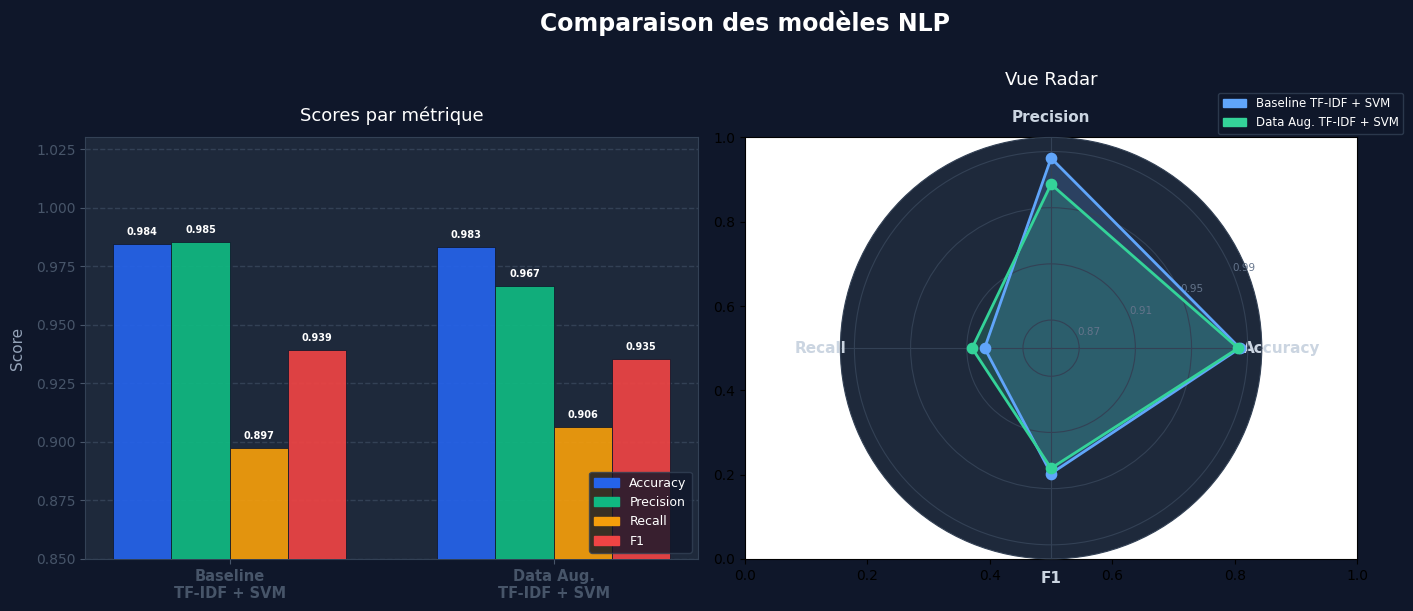

 Graphe sauvegardé : comparaison_modeles.png


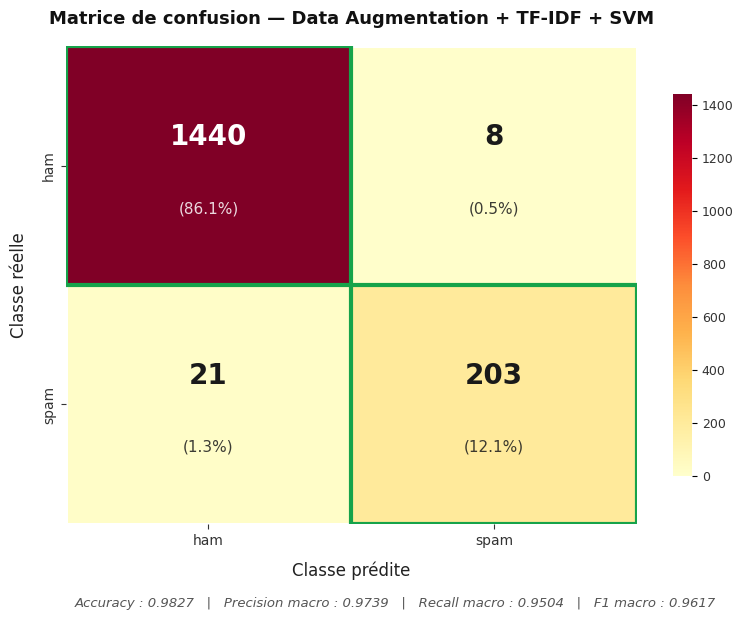

✅ Sauvegardé : confusion_matrix_aug.png


In [54]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Données ──────────────────────────────────────────────────────────────────
results_df = {
    "Model":     ["Baseline\nTF-IDF + SVM", "Data Aug.\nTF-IDF + SVM"],
    "Accuracy":  [0.984450, 0.983254],
    "Precision": [0.985294, 0.966667],
    "Recall":    [0.897321, 0.906250],
    "F1":        [0.939252, 0.935484],
}

models  = results_df["Model"]
metrics = ["Accuracy", "Precision", "Recall", "F1"]
colors  = ["#2563EB", "#10B981", "#F59E0B", "#EF4444"]   # bleu / vert / orange / rouge

x     = np.arange(len(models))
width = 0.18
n     = len(metrics)

# ── Figure ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 6), facecolor="#0F172A")
fig.suptitle(
    "Comparaison des modèles NLP",
    fontsize=17, fontweight="bold", color="white", y=1.01
)

# ── Graphe 1 : Barres groupées ────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor("#1E293B")

ax.yaxis.grid(True, color="#334155", linewidth=1, linestyle="--", zorder=0)
ax.set_axisbelow(True)

for i, (metric, color) in enumerate(zip(metrics, colors)):
    offset = (i - n / 2 + 0.5) * width
    bars = ax.bar(
        x + offset, results_df[metric], width,
        label=metric, color=color,
        edgecolor="#0F172A", linewidth=0.6,
        zorder=3, alpha=0.92
    )
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2, h + 0.003,
            f"{h:.3f}", ha="center", va="bottom",
            fontsize=7, color="white", fontweight="bold"
        )

ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=10.5, color="#CBD5E1", fontweight="600")
ax.set_ylabel("Score", fontsize=11, color="#94A3B8", labelpad=8)
ax.set_ylim(0.85, 1.03)
ax.set_title("Scores par métrique", fontsize=13, color="white", pad=12)
ax.tick_params(colors="#475569")
for spine in ax.spines.values():
    spine.set_edgecolor("#334155")

legend_patches = [mpatches.Patch(color=c, label=m) for c, m in zip(colors, metrics)]
ax.legend(handles=legend_patches, loc="lower right",
          frameon=True, facecolor="#0F172A",
          edgecolor="#334155", labelcolor="white", fontsize=9)

# ── Graphe 2 : Radar chart ────────────────────────────────────────────────────
angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()
angles += angles[:1]   # fermer le polygone

model_colors = ["#60A5FA", "#34D399"]
ax2 = fig.add_subplot(1, 2, 2, polar=True, facecolor="#1E293B")

for idx, (model, mc) in enumerate(zip(models, model_colors)):
    values = [results_df[m][idx] for m in metrics]
    values += values[:1]
    ax2.plot(angles, values, color=mc, linewidth=2, linestyle="solid", zorder=3)
    ax2.fill(angles, values, color=mc, alpha=0.20)
    ax2.scatter(angles[:-1], values[:-1], color=mc, s=55, zorder=4)

# Étiquettes des axes
ax2.set_thetagrids(np.degrees(angles[:-1]), metrics,
                   fontsize=11, color="#CBD5E1", fontweight="600")
ax2.set_ylim(0.85, 1.0)
ax2.set_yticks([0.87, 0.91, 0.95, 0.99])
ax2.set_yticklabels(["0.87", "0.91", "0.95", "0.99"],
                     fontsize=7.5, color="#64748B")
ax2.grid(color="#334155", linewidth=0.8)
ax2.spines["polar"].set_edgecolor("#334155")
ax2.set_title("Vue Radar", fontsize=13, color="white", pad=18)

# Légende radar
radar_patches = [
    mpatches.Patch(color=mc, label=m.replace("\n", " "))
    for mc, m in zip(model_colors, models)
]
ax2.legend(handles=radar_patches, loc="upper right",
           bbox_to_anchor=(1.35, 1.12),
           frameon=True, facecolor="#0F172A",
           edgecolor="#334155", labelcolor="white", fontsize=8.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "comparaison_modeles.png", dpi=150, bbox_inches="tight",
            facecolor="#0F172A")
plt.show()
print(" Graphe sauvegardé : comparaison_modeles.png")
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# ── Matrice de confusion ──────────────────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred_aug)
labels = sorted(set(y_test))

fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")
ax.set_facecolor("white")

# Normalisation pour couleur du texte adaptative
cm_norm = cm.astype(float) / cm.max()

sns.heatmap(
    cm,
    annot=False,             # annotations manuelles pour contrôle total
    cmap="YlOrRd",           # jaune → orange → rouge, lisible sur blanc
    linewidths=2,
    linecolor="white",
    xticklabels=labels,
    yticklabels=labels,
    ax=ax,
    cbar_kws={"shrink": 0.8},
    vmin=0
)

# ── Colorbar ──────────────────────────────────────────────────────────────────
cbar = ax.collections[0].colorbar
cbar.outline.set_edgecolor("#cccccc")
plt.setp(cbar.ax.yaxis.get_ticklabels(), color="#333333", fontsize=9)

# ── Annotations manuelles : valeur + % avec couleur adaptée ──────────────────
total = cm.sum()
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        val = cm[i, j]
        pct = val / total * 100
        txt_color = "white" if cm_norm[i, j] > 0.6 else "#1a1a1a"
        ax.text(j + 0.5, i + 0.38, f"{val}",
                ha="center", va="center",
                fontsize=20, fontweight="bold", color=txt_color)
        ax.text(j + 0.5, i + 0.68, f"({pct:.1f}%)",
                ha="center", va="center",
                fontsize=11, color=txt_color, alpha=0.85)

# ── Diagonale encadrée en vert ────────────────────────────────────────────────
for i in range(len(labels)):
    ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False,
                                edgecolor="#16a34a", linewidth=3, zorder=5))

# ── Labels & titre ────────────────────────────────────────────────────────────
ax.set_xlabel("Classe prédite",  fontsize=12, color="#222222", labelpad=10)
ax.set_ylabel("Classe réelle",   fontsize=12, color="#222222", labelpad=10)
ax.set_title(
    "Matrice de confusion — Data Augmentation + TF-IDF + SVM",
    fontsize=13, fontweight="bold", color="#111111", pad=16
)
ax.tick_params(colors="#333333", labelsize=10)
for spine in ax.spines.values():
    spine.set_edgecolor("#cccccc")

# ── Métriques résumées sous le graphe ────────────────────────────────────────
tp = np.diag(cm)
fp = cm.sum(axis=0) - tp
fn = cm.sum(axis=1) - tp

precision_per = tp / (tp + fp + 1e-9)
recall_per    = tp / (tp + fn + 1e-9)
f1_per        = 2 * precision_per * recall_per / (precision_per + recall_per + 1e-9)

summary = (
    f"Accuracy : {tp.sum() / cm.sum():.4f}   |   "
    f"Precision macro : {precision_per.mean():.4f}   |   "
    f"Recall macro : {recall_per.mean():.4f}   |   "
    f"F1 macro : {f1_per.mean():.4f}"
)
fig.text(0.5, -0.02, summary, ha="center", fontsize=9.5,
         color="#555555", style="italic")

plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix_aug.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()
print("✅ Sauvegardé : confusion_matrix_aug.png")

## SMOTE: Synthetic Minority Over-sampling Technique.
- Qu’est-ce que SMOTE ?
    - C’est une méthode pour équilibrer les classes dans un dataset.
    - Problème : dans beaucoup de datasets, certaines classes sont très rares. 
    - Exemple :SMS spam/ham → spam = minoritaire
    - Cela peut rendre ton modèle biaisé vers la classe majoritaire.
    - Solution : SMOTE crée de nouveaux exemples synthétiques pour la classe minoritaire, au lieu de juste dupliquer les exemples existants.
- Comment ça fonctionne ?
    - On prend chaque exemple de la classe minoritaire.
    - On cherche ses k voisins les plus proches (souvent k=5).
    - On crée un nouvel exemple synthétique en interpolant entre l’exemple et un de ses voisins
    - On répète jusqu’à ce que la classe minoritaire soit équilibrée avec la classe majoritaire.
- Points importants
    - SMOTE fonctionne sur des données numériques (pas directement sur du texte, sauf après vectorisation).
    - Il n’ajoute pas de bruit comme la duplication pure, mais génère des points réalistes.
    - Sur des datasets très petits, il peut introduire des doublons proches, donc il faut faire attention.

In [37]:
import sys
print(sys.version)
print(sys.executable)
!{sys.executable} -m pip install imblearn

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
c:\Users\0oo-u\AppData\Local\Programs\Python\Python311\python.exe
   ---------------------------------------- 0.0/235.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/235.4 kB ? eta -:--:--
   - -------------------------------------- 10.2/235.4 kB ? eta -:--:--
   ----- --------------------------------- 30.7/235.4 kB 435.7 kB/s eta 0:00:01
   ------ -------------------------------- 41.0/235.4 kB 326.8 kB/s eta 0:00:01
   ---------- ---------------------------- 61.4/235.4 kB 328.2 kB/s eta 0:00:01
   ----------- --------------------------- 71.7/235.4 kB 302.7 kB/s eta 0:00:01
   --------------- ----------------------- 92.2/235.4 kB 327.7 kB/s eta 0:00:01
   ---------------- --------------------- 102.4/235.4 kB 310.3 kB/s eta 0:00:01
   ------------------- ------------------ 122.9/235.4 kB 327.4 kB/s eta 0:00:01
   ----------------------- -------------- 143.4/235.4 kB 355.0 kB/s eta 0:00:01


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

#### 1 Pipeline SMOTE 

In [39]:
smote_pipeline = ImbPipeline([
    ('tfidf', TfidfVectorizer()),
    ('smote', SMOTE(random_state=42)),
    ('svm', SVC(kernel='linear'))
])

#### 3 Entraînement

In [40]:
smote_pipeline.fit(X_train_original, y_train_original)

,steps,"[('tfidf', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


#### 4 Prédiction

In [41]:
y_pred_smote = smote_pipeline.predict(X_test)

#### 5 Évaluation

In [47]:
smote_results = {
    "Model": "SMOTE",
    "Accuracy": accuracy_score(y_test, y_pred_smote),
    "Precision": precision_score(y_test, y_pred_smote, pos_label="spam"),
    "Recall": recall_score(y_test, y_pred_smote, pos_label="spam"),
    "F1": f1_score(y_test, y_pred_smote, pos_label="spam")
}
results_df = pd.DataFrame([baseline_results,smote_results])
print(results_df)

print("\nMatrice de confusion (SMOTE):\n")
print(confusion_matrix(y_test, y_pred_smote))

                   Model  Accuracy  Precision    Recall        F1
0  Baseline TF-IDF + SVM  0.984450   0.985294  0.897321  0.939252
1                  SMOTE  0.983254   0.957944  0.915179  0.936073

Matrice de confusion (SMOTE):

[[1439    9]
 [  19  205]]


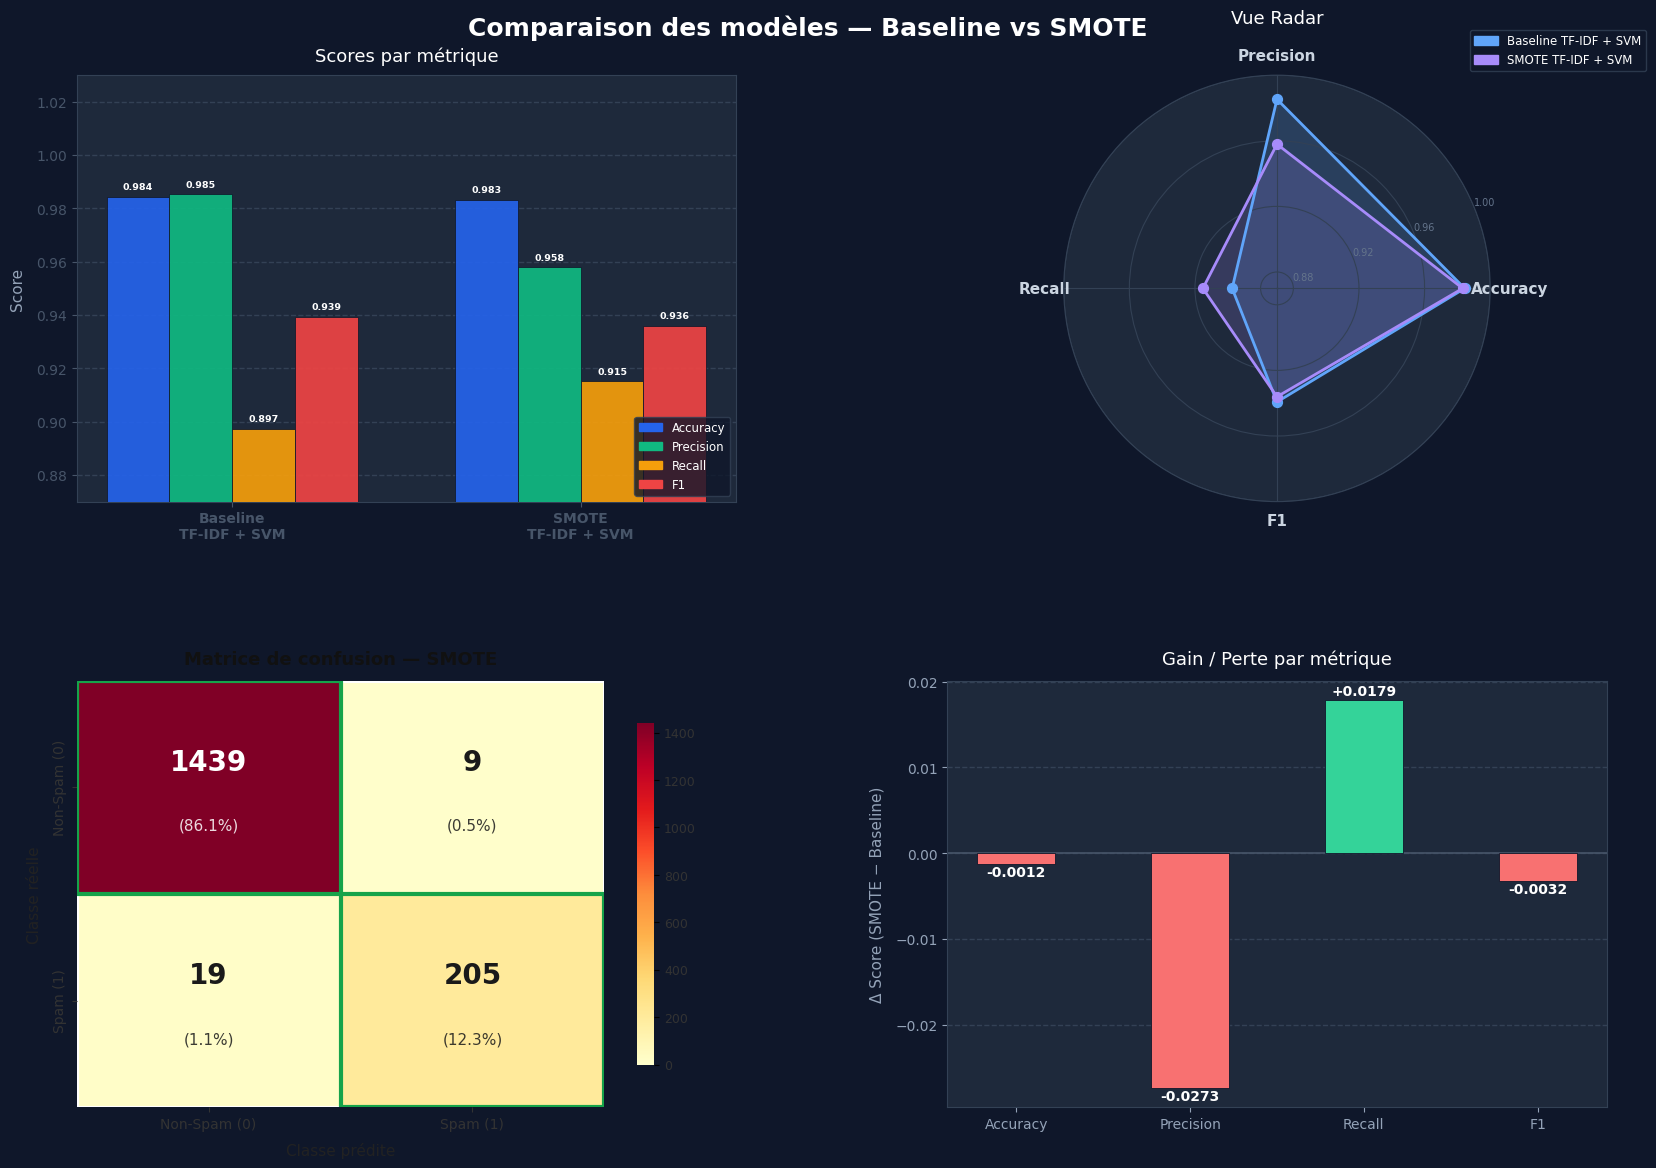

✅ Sauvegardé : comparaison_smote.png


In [52]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np

# ── Données ───────────────────────────────────────────────────────────────────
results_df = {
    "Model":     ["Baseline\nTF-IDF + SVM", "SMOTE\nTF-IDF + SVM"],
    "Accuracy":  [0.984450, 0.983254],
    "Precision": [0.985294, 0.957944],
    "Recall":    [0.897321, 0.915179],
    "F1":        [0.939252, 0.936073],
}

cm_smote = np.array([[1439, 9],
                      [  19, 205]])
class_labels = ["Non-Spam (0)", "Spam (1)"]

metrics      = ["Accuracy", "Precision", "Recall", "F1"]
model_colors = ["#60A5FA", "#A78BFA"]
bar_colors   = ["#2563EB", "#10B981", "#F59E0B", "#EF4444"]

# ── Layout 2×2 ────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(17, 12), facecolor="#0F172A")
fig.suptitle("Comparaison des modèles — Baseline vs SMOTE",
             fontsize=18, fontweight="bold", color="white", y=0.98)

gs = fig.add_gridspec(2, 2, hspace=0.42, wspace=0.32,
                      left=0.07, right=0.97, top=0.93, bottom=0.07)

ax_bar   = fig.add_subplot(gs[0, 0])
ax_radar = fig.add_subplot(gs[0, 1], polar=True)
ax_cm    = fig.add_subplot(gs[1, 0])
ax_diff  = fig.add_subplot(gs[1, 1])

# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 1) Barres groupées
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ax_bar.set_facecolor("#1E293B")
ax_bar.yaxis.grid(True, color="#334155", linewidth=1, linestyle="--", zorder=0)
ax_bar.set_axisbelow(True)

x     = np.arange(len(results_df["Model"]))
width = 0.18
n     = len(metrics)

for i, (metric, color) in enumerate(zip(metrics, bar_colors)):
    offset = (i - n / 2 + 0.5) * width
    bars = ax_bar.bar(x + offset, results_df[metric], width,
                      color=color, edgecolor="#0F172A", linewidth=0.6,
                      zorder=3, alpha=0.92)
    for bar in bars:
        h = bar.get_height()
        ax_bar.text(bar.get_x() + bar.get_width() / 2, h + 0.002,
                    f"{h:.3f}", ha="center", va="bottom",
                    fontsize=6.8, color="white", fontweight="bold")

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(results_df["Model"], fontsize=10, color="#CBD5E1", fontweight="600")
ax_bar.set_ylabel("Score", fontsize=11, color="#94A3B8", labelpad=8)
ax_bar.set_ylim(0.87, 1.03)
ax_bar.set_title("Scores par métrique", fontsize=13, color="white", pad=10)
ax_bar.tick_params(colors="#475569")
for spine in ax_bar.spines.values():
    spine.set_edgecolor("#334155")

legend_patches = [mpatches.Patch(color=c, label=m) for c, m in zip(bar_colors, metrics)]
ax_bar.legend(handles=legend_patches, loc="lower right",
              frameon=True, facecolor="#0F172A",
              edgecolor="#334155", labelcolor="white", fontsize=8.5)

# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 2) Radar chart
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ax_radar.set_facecolor("#1E293B")
angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()
angles += angles[:1]

for idx, (model, mc) in enumerate(zip(results_df["Model"], model_colors)):
    values = [results_df[m][idx] for m in metrics] + [results_df[metrics[0]][idx]]
    ax_radar.plot(angles, values, color=mc, linewidth=2, zorder=3)
    ax_radar.fill(angles, values, color=mc, alpha=0.18)
    ax_radar.scatter(angles[:-1], values[:-1], color=mc, s=50, zorder=4)

ax_radar.set_thetagrids(np.degrees(angles[:-1]), metrics,
                        fontsize=11, color="#CBD5E1", fontweight="600")
ax_radar.set_ylim(0.87, 1.0)
ax_radar.set_yticks([0.88, 0.92, 0.96, 1.00])
ax_radar.set_yticklabels(["0.88", "0.92", "0.96", "1.00"],
                          fontsize=7, color="#64748B")
ax_radar.grid(color="#334155", linewidth=0.8)
ax_radar.spines["polar"].set_edgecolor("#334155")
ax_radar.set_title("Vue Radar", fontsize=13, color="white", pad=18)

radar_patches = [mpatches.Patch(color=mc, label=m.replace("\n", " "))
                 for mc, m in zip(model_colors, results_df["Model"])]
ax_radar.legend(handles=radar_patches, loc="upper right",
                bbox_to_anchor=(1.38, 1.12),
                frameon=True, facecolor="#0F172A",
                edgecolor="#334155", labelcolor="white", fontsize=8.5)

# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 3) Matrice de confusion — fond blanc, texte foncé, contraste maximal
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ax_cm.set_facecolor("white")

# Normalisation pour choisir la couleur du texte automatiquement
cm_norm = cm_smote.astype(float) / cm_smote.max()

sns.heatmap(
    cm_smote,
    annot=False,            # on gère les annotations manuellement
    fmt="d",
    cmap="YlOrRd",          # jaune → orange → rouge  (lisible sur fond blanc)
    linewidths=2,
    linecolor="white",
    xticklabels=class_labels,
    yticklabels=class_labels,
    ax=ax_cm,
    cbar_kws={"shrink": 0.8},
    vmin=0
)

# Annotations manuelles : valeur + pourcentage, couleur adaptée au fond
total = cm_smote.sum()
for i in range(2):
    for j in range(2):
        val  = cm_smote[i, j]
        pct  = val / total * 100
        # Texte noir sur cases claires, blanc sur cases foncées
        txt_color = "white" if cm_norm[i, j] > 0.6 else "#1a1a1a"
        ax_cm.text(j + 0.5, i + 0.38, f"{val}",
                   ha="center", va="center",
                   fontsize=20, fontweight="bold", color=txt_color)
        ax_cm.text(j + 0.5, i + 0.68, f"({pct:.1f}%)",
                   ha="center", va="center",
                   fontsize=11, color=txt_color, alpha=0.85)

# Encadrer la diagonale en vert
for i in range(2):
    ax_cm.add_patch(plt.Rectangle((i, i), 1, 1, fill=False,
                                   edgecolor="#16a34a", linewidth=3, zorder=5))

# Colorbar lisible
cbar = ax_cm.collections[0].colorbar
cbar.outline.set_edgecolor("#cccccc")
plt.setp(cbar.ax.yaxis.get_ticklabels(), color="#333333", fontsize=9)

ax_cm.set_xlabel("Classe prédite",  fontsize=11, color="#222222", labelpad=8)
ax_cm.set_ylabel("Classe réelle",   fontsize=11, color="#222222", labelpad=8)
ax_cm.set_title("Matrice de confusion — SMOTE", fontsize=13,
                fontweight="bold", color="#111111", pad=12)
ax_cm.tick_params(colors="#333333", labelsize=10)
for spine in ax_cm.spines.values():
    spine.set_edgecolor("#cccccc")

# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 4) Delta
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ax_diff.set_facecolor("#1E293B")
ax_diff.yaxis.grid(True, color="#334155", linewidth=1, linestyle="--", zorder=0)
ax_diff.axhline(0, color="#475569", linewidth=1.2, zorder=1)
ax_diff.set_axisbelow(True)

deltas   = [results_df[m][1] - results_df[m][0] for m in metrics]
d_colors = ["#34D399" if d >= 0 else "#F87171" for d in deltas]

bars_d = ax_diff.bar(metrics, deltas, color=d_colors,
                      edgecolor="#0F172A", linewidth=0.6, zorder=3, width=0.45)

for bar, d in zip(bars_d, deltas):
    va  = "bottom" if d >= 0 else "top"
    off = 0.0002 if d >= 0 else -0.0002
    ax_diff.text(bar.get_x() + bar.get_width() / 2, d + off,
                 f"{d:+.4f}", ha="center", va=va,
                 fontsize=10, color="white", fontweight="bold")

ax_diff.set_ylabel("Δ Score (SMOTE − Baseline)", fontsize=11,
                    color="#94A3B8", labelpad=8)
ax_diff.set_title("Gain / Perte par métrique", fontsize=13,
                   color="white", pad=12)
ax_diff.tick_params(colors="#94A3B8", labelsize=10)
for spine in ax_diff.spines.values():
    spine.set_edgecolor("#334155")

plt.savefig(FIG_DIR / "comparaison_smote.png", dpi=150,
            bbox_inches="tight", facecolor="#0F172A")
plt.show()
print("✅ Sauvegardé : comparaison_smote.png")

## Comparaison Finale

In [43]:
results_df = pd.DataFrame([
    baseline_results,
    aug_results,
    smote_results
])

print(results_df)

                   Model  Accuracy  Precision    Recall        F1
0  Baseline TF-IDF + SVM  0.984450   0.985294  0.897321  0.939252
1      Data Augmentation  0.982656   0.962085  0.906250  0.933333
2                  SMOTE  0.983254   0.957944  0.915179  0.936073


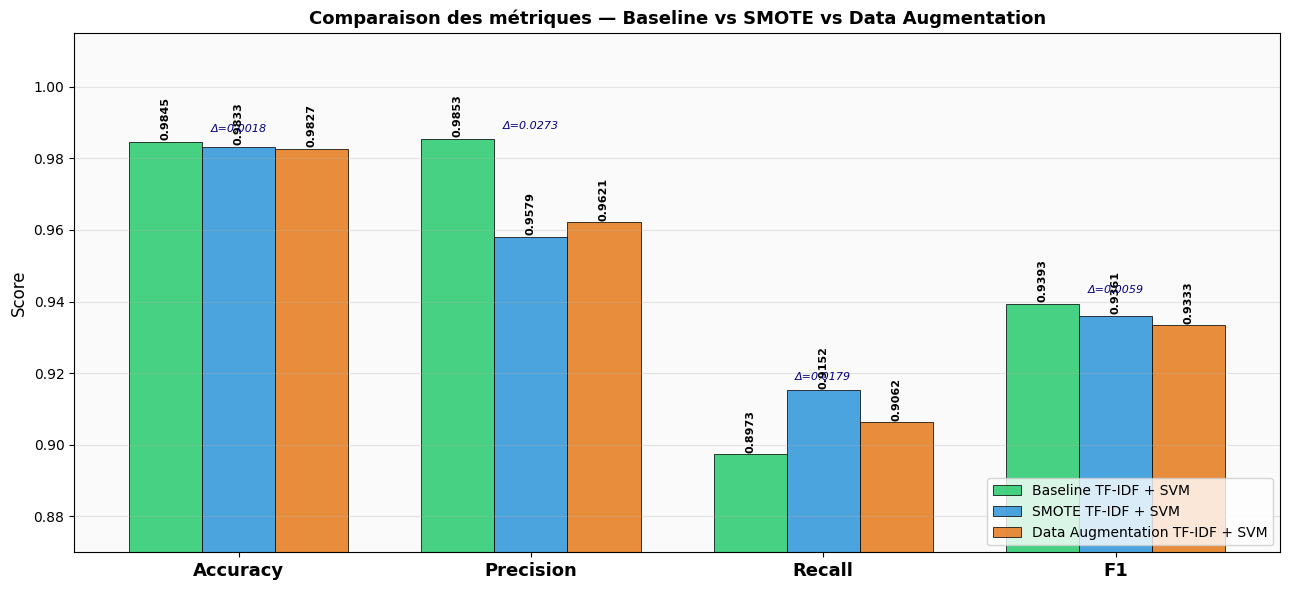

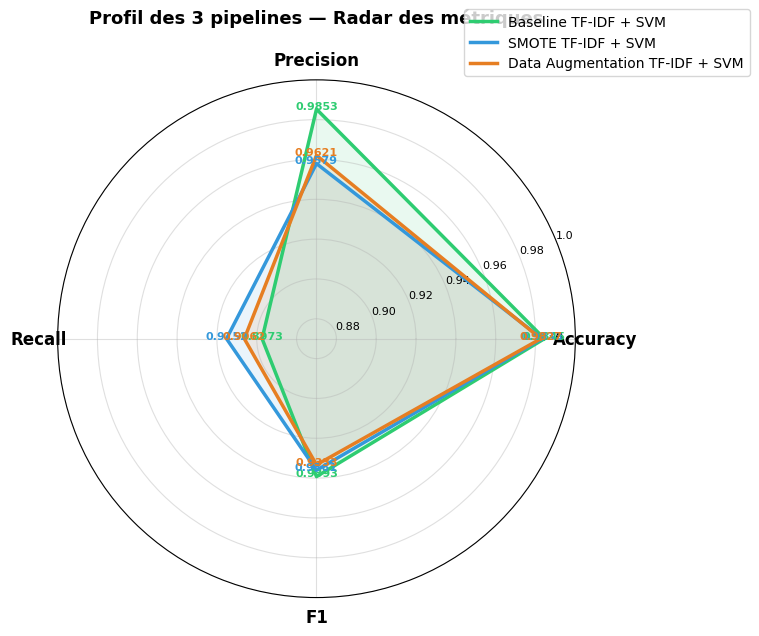

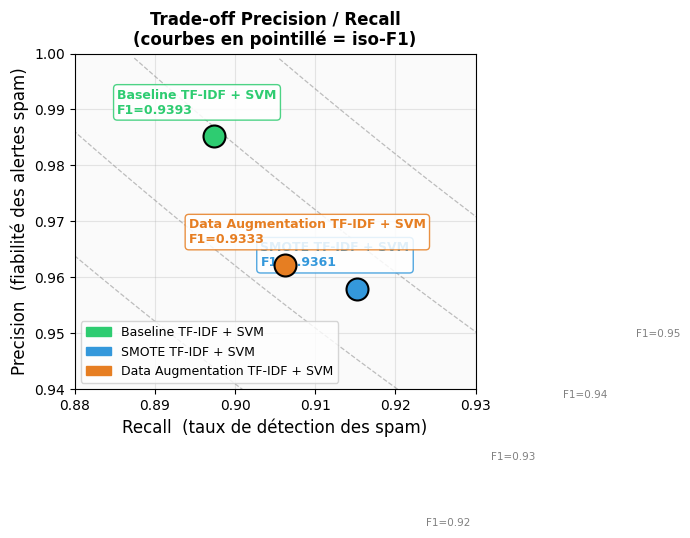

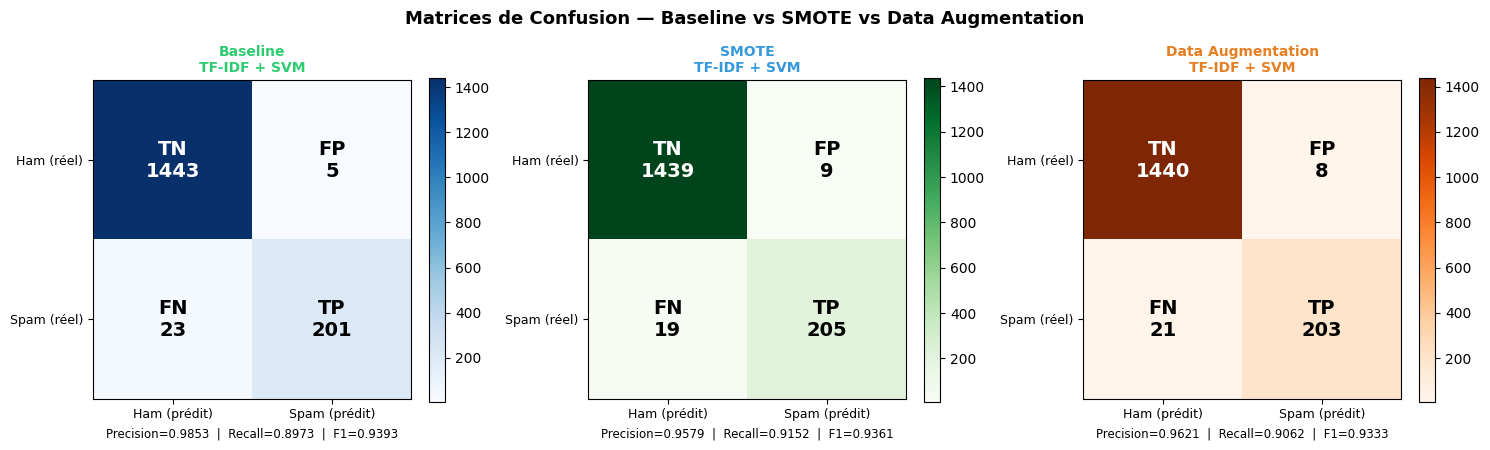

C:\Users\0oo-u\AppData\Local\Temp\ipykernel_24572\3170237515.py:247: UserWarning: Glyph 129351 (\N{FIRST PLACE MEDAL}) missing from font(s) DejaVu Sans.
  plt.savefig("fig5_tableau_synthese.png", dpi=150, bbox_inches="tight")
C:\Users\0oo-u\AppData\Local\Temp\ipykernel_24572\3170237515.py:247: UserWarning: Glyph 129352 (\N{SECOND PLACE MEDAL}) missing from font(s) DejaVu Sans.
  plt.savefig("fig5_tableau_synthese.png", dpi=150, bbox_inches="tight")
C:\Users\0oo-u\AppData\Local\Temp\ipykernel_24572\3170237515.py:247: UserWarning: Glyph 129353 (\N{THIRD PLACE MEDAL}) missing from font(s) DejaVu Sans.
  plt.savefig("fig5_tableau_synthese.png", dpi=150, bbox_inches="tight")
C:\Users\0oo-u\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129351 (\N{FIRST PLACE MEDAL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\0oo-u\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWar

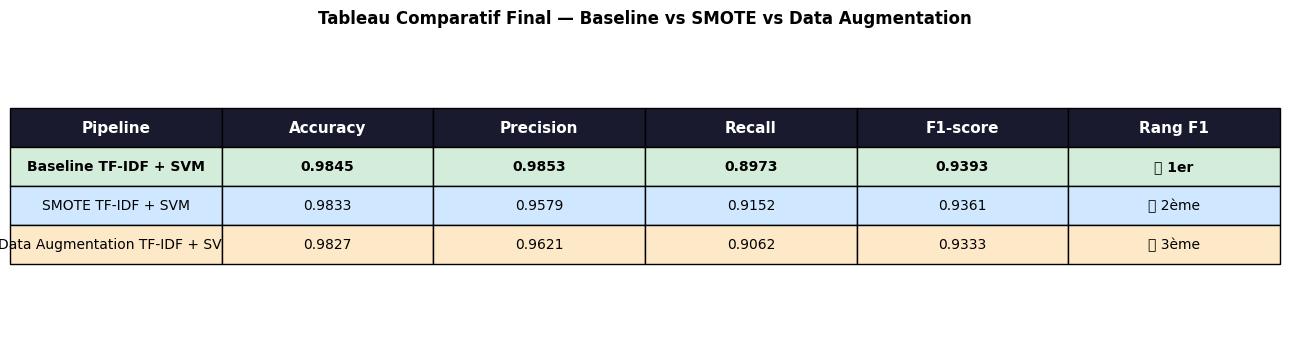

  SYNTHÈSE — COMPARAISON DES 3 PIPELINES

  Baseline TF-IDF + SVM
    Accuracy  = 0.9845
    Precision = 0.9853
    Recall    = 0.8973
    F1-score  = 0.9393

  SMOTE TF-IDF + SVM
    Accuracy  = 0.9833
    Precision = 0.9579
    Recall    = 0.9152
    F1-score  = 0.9361

  Data Augmentation TF-IDF + SVM
    Accuracy  = 0.9827
    Precision = 0.9621
    Recall    = 0.9062
    F1-score  = 0.9333

  SMOTE améliore le Recall (+0.018) mais dégrade la Precision (-0.027)
  Data Augmentation : profil intermédiaire
  Baseline : meilleur F1 global (0.9393)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ================================================================
# DONNÉES RÉELLES — 3 pipelines à comparer
# ================================================================

donnees = {
    "Baseline\nTF-IDF + SVM":        {"Accuracy": 0.984450, "Precision": 0.985294, "Recall": 0.897321, "F1": 0.939252},
    "SMOTE\nTF-IDF + SVM":           {"Accuracy": 0.983254, "Precision": 0.957944, "Recall": 0.915179, "F1": 0.936073},
    "Data Augmentation\nTF-IDF + SVM":{"Accuracy": 0.982656, "Precision": 0.962085, "Recall": 0.906250, "F1": 0.933333},
}

labels   = list(donnees.keys())
metrics  = ["Accuracy", "Precision", "Recall", "F1"]
colors   = ["#2ecc71", "#3498db", "#e67e22"]

df = pd.DataFrame(donnees).T.reset_index()
df.columns = ["Pipeline", "Accuracy", "Precision", "Recall", "F1"]

# Matrices de confusion réelles
cms = {
    "Baseline\nTF-IDF + SVM":         np.array([[1443, 5], [23, 201]]),
    "SMOTE\nTF-IDF + SVM":            np.array([[1439, 9], [19, 205]]),
    "Data Augmentation\nTF-IDF + SVM":np.array([[1440, 8], [21, 203]]),
}

# ================================================================
# FIGURE 1 — Comparaison des 4 métriques (barres groupées)
# ================================================================

fig1, ax = plt.subplots(figsize=(13, 6))

x   = np.arange(len(metrics))
w   = 0.25
off = [-w, 0, w]

for i, (label, color) in enumerate(zip(labels, colors)):
    vals = [donnees[label][m] for m in metrics]
    bars = ax.bar(x + off[i], vals, width=w, label=label.replace("\n", " "),
                  color=color, edgecolor="black", linewidth=0.6, alpha=0.88)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.0005,
                f"{val:.4f}", ha="center", va="bottom", fontsize=8, fontweight="bold",
                rotation=90)

ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=13, fontweight="bold")
ax.set_ylim(0.87, 1.015)
ax.set_ylabel("Score", fontsize=12)
ax.set_title("Comparaison des métriques — Baseline vs SMOTE vs Data Augmentation",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=10, loc="lower right")
ax.grid(axis="y", alpha=0.3)
ax.set_facecolor("#fafafa")

# Annotations différences
for i, m in enumerate(metrics):
    vals = [donnees[l][m] for l in labels]
    best = max(vals)
    worst = min(vals)
    ax.annotate(f"Δ={best-worst:.4f}", xy=(i, best + 0.003),
                ha="center", fontsize=8, color="navy", style="italic")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_metriques_comparaison.png", dpi=150, bbox_inches="tight")
plt.show()

# ================================================================
# FIGURE 2 — Radar / Spider chart des 4 métriques
# ================================================================

from matplotlib.patches import FancyArrowPatch

cat    = metrics + [metrics[0]]   # boucler
angles = np.linspace(0, 2*np.pi, len(metrics), endpoint=False).tolist()
angles += angles[:1]

fig2, ax2 = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for label, color in zip(labels, colors):
    vals = [donnees[label][m] for m in metrics]
    vals += vals[:1]
    ax2.plot(angles, vals, color=color, linewidth=2.5,
             label=label.replace("\n", " "))
    ax2.fill(angles, vals, color=color, alpha=0.10)
    for angle, val in zip(angles[:-1], vals[:-1]):
        ax2.annotate(f"{val:.4f}",
                     xy=(angle, val), fontsize=8, ha="center",
                     color=color, fontweight="bold")

ax2.set_xticks(angles[:-1])
ax2.set_xticklabels(metrics, fontsize=12, fontweight="bold")
ax2.set_ylim(0.87, 1.0)
ax2.set_yticks([0.88, 0.90, 0.92, 0.94, 0.96, 0.98, 1.0])
ax2.set_yticklabels(["0.88","0.90","0.92","0.94","0.96","0.98","1.0"], fontsize=8)
ax2.set_title("Profil des 3 pipelines — Radar des métriques",
              fontsize=13, fontweight="bold", pad=20)
ax2.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15), fontsize=10)
ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_radar.png", dpi=150, bbox_inches="tight")
plt.show()

# ================================================================
# FIGURE 3 — Precision vs Recall (trade-off)
# ================================================================

fig3, ax3 = plt.subplots(figsize=(8, 6))

for label, color in zip(labels, colors):
    p = donnees[label]["Precision"]
    r = donnees[label]["Recall"]
    f = donnees[label]["F1"]
    ax3.scatter(r, p, s=250, color=color, edgecolors="black",
                linewidth=1.5, zorder=5)
    ax3.annotate(f"{label.replace(chr(10), ' ')}\nF1={f:.4f}",
                 xy=(r, p), xytext=(r - 0.012, p + 0.004),
                 fontsize=9, fontweight="bold", color=color,
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                           edgecolor=color, alpha=0.85))

# Courbes iso-F1
for f1_val in [0.92, 0.93, 0.94, 0.95]:
    r_range = np.linspace(0.80, 1.0, 200)
    p_iso   = (f1_val * r_range) / (2 * r_range - f1_val)
    p_iso   = np.where((p_iso > 0) & (p_iso <= 1), p_iso, np.nan)
    ax3.plot(r_range, p_iso, "--", color="gray", linewidth=0.9, alpha=0.5)
    valid = ~np.isnan(p_iso)
    if valid.any():
        idx = np.where(valid)[0][len(np.where(valid)[0])//2]
        ax3.text(r_range[idx], p_iso[idx] + 0.002,
                 f"F1={f1_val}", fontsize=7.5, color="gray", ha="center")

ax3.set_xlabel("Recall  (taux de détection des spam)", fontsize=12)
ax3.set_ylabel("Precision  (fiabilité des alertes spam)", fontsize=12)
ax3.set_title("Trade-off Precision / Recall\n(courbes en pointillé = iso-F1)",
              fontsize=12, fontweight="bold")
ax3.set_xlim(0.88, 0.93)
ax3.set_ylim(0.94, 1.0)
ax3.grid(True, alpha=0.3)
ax3.set_facecolor("#fafafa")
legend_els = [mpatches.Patch(color=c, label=l.replace("\n", " "))
              for l, c in zip(labels, colors)]
ax3.legend(handles=legend_els, fontsize=9, loc="lower left")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_precision_recall.png", dpi=150, bbox_inches="tight")
plt.show()

# ================================================================
# FIGURE 4 — Matrices de confusion côte à côte
# ================================================================

fig4, axes4 = plt.subplots(1, 3, figsize=(15, 4.5))
class_labels = ["Ham", "Spam"]
cmap_list = ["Blues", "Greens", "Oranges"]

for ax_cm, (titre, cm), color_map, main_color in zip(
        axes4, cms.items(), cmap_list, colors):

    im = ax_cm.imshow(cm, interpolation="nearest", cmap=color_map)
    ax_cm.set_title(titre.replace("\n", "\n"), fontsize=10, fontweight="bold",
                    color=main_color)
    ax_cm.set_xticks([0, 1])
    ax_cm.set_yticks([0, 1])
    ax_cm.set_xticklabels(["Ham (prédit)", "Spam (prédit)"], fontsize=9)
    ax_cm.set_yticklabels(["Ham (réel)", "Spam (réel)"], fontsize=9)

    thresh = cm.max() / 2
    annot_labels = [["TN", "FP"], ["FN", "TP"]]
    for i in range(2):
        for j in range(2):
            txt_color = "white" if cm[i, j] > thresh else "black"
            ax_cm.text(j, i, f"{annot_labels[i][j]}\n{cm[i,j]}",
                       ha="center", va="center", fontsize=14,
                       fontweight="bold", color=txt_color)
    plt.colorbar(im, ax=ax_cm, fraction=0.046)

    # Métriques sous le graphe
    p  = donnees[titre]["Precision"]
    r  = donnees[titre]["Recall"]
    f1 = donnees[titre]["F1"]
    ax_cm.set_xlabel(f"Precision={p:.4f}  |  Recall={r:.4f}  |  F1={f1:.4f}",
                     fontsize=8.5)

plt.suptitle("Matrices de Confusion — Baseline vs SMOTE vs Data Augmentation",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_matrices_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

# ================================================================
# FIGURE 5 — Tableau synthèse visuel
# ================================================================

fig5, ax5 = plt.subplots(figsize=(13, 3.5))
ax5.axis("off")

col_labels = ["Pipeline", "Accuracy", "Precision", "Recall", "F1-score", "Rang F1"]
ranks = [" 1er", " 3ème", " 2ème"]   # ordre df

cell_text = []
cell_colors = []

sorted_df = df.sort_values("F1", ascending=False).reset_index(drop=True)

rank_map = {"Baseline\nTF-IDF + SVM": " 1er",
            "SMOTE\nTF-IDF + SVM": " 2ème",
            "Data Augmentation\nTF-IDF + SVM": " 3ème"}
color_map_row = {"Baseline\nTF-IDF + SVM": "#d4edda",
                 "SMOTE\nTF-IDF + SVM": "#d0e8ff",
                 "Data Augmentation\nTF-IDF + SVM": "#fde8c8"}

for _, row in sorted_df.iterrows():
    key = row["Pipeline"]
    bg  = color_map_row.get(key, "#f7f7f7")
    cell_text.append([
        key.replace("\n", " "),
        f"{row['Accuracy']:.4f}",
        f"{row['Precision']:.4f}",
        f"{row['Recall']:.4f}",
        f"{row['F1']:.4f}",
        rank_map.get(key, "")
    ])
    cell_colors.append([bg] * 6)

tbl = ax5.table(cellText=cell_text, colLabels=col_labels,
                cellColours=cell_colors, cellLoc="center", loc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 2.2)

for j in range(len(col_labels)):
    tbl[0, j].set_facecolor("#1a1a2e")
    tbl[0, j].set_text_props(color="white", fontweight="bold", fontsize=11)
for j in range(len(col_labels)):
    tbl[1, j].set_text_props(fontweight="bold")

ax5.set_title("Tableau Comparatif Final — Baseline vs SMOTE vs Data Augmentation",
              fontsize=12, fontweight="bold", pad=14)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig5_tableau_synthese.png", dpi=150, bbox_inches="tight")
plt.show()

print("=" * 62)
print("  SYNTHÈSE — COMPARAISON DES 3 PIPELINES")
print("=" * 62)
for label in labels:
    d = donnees[label]
    print(f"\n  {label.replace(chr(10), ' ')}")
    print(f"    Accuracy  = {d['Accuracy']:.4f}")
    print(f"    Precision = {d['Precision']:.4f}")
    print(f"    Recall    = {d['Recall']:.4f}")
    print(f"    F1-score  = {d['F1']:.4f}")
print()
print("  SMOTE améliore le Recall (+0.018) mais dégrade la Precision (-0.027)")
print("  Data Augmentation : profil intermédiaire")
print("  Baseline : meilleur F1 global (0.9393)")
print("=" * 62)